# Plan noise vs plan-first prompting for code — demo

*Iteration-5 experiment (`experiment-27`): **Qwen3-8B** (revision `b968826d`) writing Python for algorithm tasks.*

Qwen3-8B nearly always writes one **default algorithm** per task: a full sort for the k-th smallest element, heap Dijkstra for a weighted shortest path. The artifact asks which *knob* buys **correct algorithmic diversity**: more distinct algorithms that still pass the hidden tests, for little loss of pass rate.

**Claim C: plan noise against plan-first prompting.**

- **Plan noise (PN).** A per-sample isotropic random direction is added to the residual stream at the task-specification positions of decoder blocks 12–23. It acts during the prompt prefill only, scaled to the ban-free unit ‖h‖·r_Q, at α ∈ {1, 2}.
- **Text-level plan samplers.** PN is compared with four frame-matched samplers:
  - **IFG**: an intent sentence sampled hot, then the code;
  - **PSL**: PlanSearch-lite;
  - **EAP**: enumerate-and-pick;
  - **BINT**: Qwen3-8B-*Base* writes the intent.
- **Departure-matched decoding (DMD).** PN is also compared with a temperature on tokens 1–32, matched to PN's per-token KL.
- **Pricing.** Every knob is priced on a randomisation hull. **H5** is the largest correct-only Hill-1 diversity reachable while losing at most 5 pass-rate points.
- **Committed verdict: DISCONFIRMED.** PN matches or beats the best text sampler on only 1 of the 5 decisive tasks.

**Claim F: the literal cell.** On the shortest-path task T2, with thinking on, top-k 10 and a fixed seed, does temperature ∈ {0.3, 0.7, 1.0, 1.3} ever change the algorithm? No: 0 of 20 seeds change, and every program is heap Dijkstra.

**What this notebook runs.**

- **Not re-run.** The generation and labelling stages need a 24 GB GPU (about 2 GPU-hours with vLLM and an HF bf16 engine) and LLM judges.
- **The data.** Their output, the labelled programs, is what `mini_demo_data.json` holds for two of the five decisive tasks: **T03** (k-th smallest element) and **T2** (weighted shortest path, the "implement a path-search algorithm" task). It covers every slot (5 prompt templates × 10 seeds) and every knob arm, which is 100 slots and 1,550 labelled programs.
- **Re-run.** The notebook runs the CPU **`analyze` stage for Claim C** on that data: `src/analysis_c.py` with the hull code in `src/hull_exp20.py` and `src/hull_full.py`. It then runs the figure code in `src/figures5.py`. The code is copied nearly verbatim and split into cells; every change is marked with a `# notebook:` comment.
- **Comparison.** The last cells compare the recomputed numbers with the committed full run. The point prices and McNemar tests reproduce exactly.

**Runtime.** About 2.5 minutes on 2 CPUs with the default configuration, most of it the bootstrap. Expect roughly twice that on Colab's free tier.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru — NOT pre-installed on Colab, always install (method.py's logger)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib — pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py (the orchestrator)
import subprocess
import sys
import time
from pathlib import Path

from loguru import logger

# --- src/analysis_c.py
import json
import math
import multiprocessing as mp
from collections import Counter, defaultdict
from concurrent.futures import ProcessPoolExecutor
from typing import Any

import numpy as np

# --- src/hull_exp20.py, src/hull_full.py
import itertools

# --- src/parsers.py (map_modes) and src/cfg.py (utc_now)
import re
from datetime import datetime, timezone

# --- notebook addition: the figures (src/figures5.py draws with matplotlib)
import matplotlib.pyplot as plt

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/experiment-27/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
meta = data["metadata"]
print(meta["title"])
print(f"{meta['n_examples']} slot examples, {meta['n_rows']} labelled programs; dataset: {meta['dataset']}")
for t, s in meta["task_descriptions"].items():
    print(f"  {t}: {s}")
ex = data["examples"][0]
print(f"first example: {ex['input']} -> TWIN '{ex['output']}'; arms at this slot: {sorted(r['arm'] for r in ex['rows'])}")

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
Plan noise vs plan-first prompting for code (iteration 5) - demo subset
100 slot examples, 1550 labelled programs; dataset: knob_slots (data/samples_raw.jsonl + data/labels.jsonl merged by sample_id)
  T03: k-th smallest element of a list (default: a full sort)
  T2: weighted single-source shortest path (default: heap Dijkstra)
first example: T03|W1|k=0 -> TWIN 'full_sort|pass'; arms at this slot: ['BINT', 'DMD_a1', 'DMD_a2', 'EAP', 'IFG_hot', 'IFG_paper', 'NOVELTY', 'PLAIN', 'PNPLAIN_a1', 'PN_a1', 'PN_a2', 'PSL', 'T1.3', 'TOPK10', 'TWIN']


## Configuration

Every tunable parameter is set here, with the committed run's value in the comment beside it.

- **Point prices** (`N_DRAWS_POINT`, `N_RAREFY`) run at the committed values. That takes about 25 s for both tasks, and it reproduces the committed H5, P15 and P20 exactly.
- **The slot bootstrap** is the expensive part, at about 0.1 s per replicate per task on 2 CPUs. It is scaled down from 2,000 to 500 replicates per decisive task.
- **Replicate seeds** are the committed ones (`BOOT_SEED5 * 1000 + i + 7919 * task_index`). Each demo replicate is identical to the committed run's replicate for the same seed, which was checked against the artifact's `results/boot_cache/`. `N_BOOT_D5 = 2000` therefore reproduces the committed bootstrap exactly, at the cost of about 5 more minutes.

With these values the notebook ran in about 2.5 minutes on 2 CPUs. Expect roughly twice that on Colab's free tier.

In [5]:
# ---- tunable parameters ------------------------------------------------------------------------------------------
# Demo values; the committed run's values are in the comments (src/cfg5.py and the run() defaults of analysis_c.py).
# Measured on 2 CPUs: the whole notebook ~2.5 min, of which the bootstrap ~100 s (about 0.1 s per replicate per task).
N_DRAWS_POINT = 1000   # CRN draws per point price (H5 / P15 / P20) and per sensitivity price   (original: 1000)
N_RAREFY = 1000        # subsamples of each cell's rarefied Hill-1                               (original: 1000)
N_BOOT_D5 = 500        # slot-bootstrap replicates per decisive task                             (original: 2000;
                       #   2000 reproduces the committed bootstrap exactly but adds ~5 min here, more on Colab)
N_BOOT_ND = 500        # replicates per non-decisive task (none in this subset, so unused here) (original: 500)
BOOT_RAREFY = 200      # CRN draws per hull inside one bootstrap replicate                       (original: 200)
N_WORKERS = 10         # seed chunks of the bootstrap. The committed D5 replicates (results/boot_cache) were drawn in
                       # 10 chunks (the script's CLI default is 12); the notebook runs the chunks one after another,
                       # and 10 chunks give back the committed replicates in the committed order

## 1. The pipeline — `method.py`

`method.py` is a thin orchestrator. Every stage is a script under `src/` that resumes from what is already on disk, and `main()` launches the stages one after another as subprocesses. The vLLM stage runs in `.venv_vllm`; every other stage runs in `.venv`.

| stage | what it does | in this notebook |
|---|---|---|
| `s0`, `prompts`, `commit0F` / `commit0C` / `commit1` | hardware and precision rule, input hashes and seed registry, the 430 stage-1 prompts, the sha256 pre-registration chain | not re-run |
| `literal`, `label_f` | Claim F: 100 thinking-on traces on vLLM (FP8) and their frozen labels | not re-run; the committed result is printed at the end |
| `gpu`, `label` | base intents, DMD calibration, the engine check, the knob queue (7,060 programs); frozen mechanism labellers (runtime trace + AST, a judge on disagreement) | not re-run; 1,550 of the labelled rows are `mini_demo_data.json` |
| `audit` | lexicon audit, style re-gate, novelty audit (LLM judges) | not re-run; their flags are in the data |
| `analyze` | `analysis_f` (Claim F), `analysis_ec` (engine check), **`analysis_c` (Claim C)** | **`analysis_c` runs below** |
| `figures` | F1–F6 | **F2–F6 run below** |
| `outputs`, `rederive` | `method_out.json`, the independent re-derivation and placebos | not re-run |

The next cell is `method.py` itself. Only `ROOT` changes, because a notebook has no `__file__`. `main()` is defined but not called, since it would launch the GPU stages.

In [6]:
# method.py, verbatim except ROOT: a notebook has no __file__, so the notebook's folder plays the artifact root.
ROOT = Path.cwd()  # original: Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")
PYV = str(ROOT / ".venv_vllm" / "bin" / "python")
(ROOT / "logs").mkdir(exist_ok=True)
logger.remove()
logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
logger.add(str(ROOT / "logs" / "method.log"), rotation="30 MB", level="DEBUG")

STAGES: dict[str, list[list[str]]] = {
    "s0": [[PY, "src/s0.py", "all"]],
    "prompts": [[PY, "src/prompts5.py"]],
    "commit0F": [[PY, "src/prereg5.py", "commit0F"]],
    "literal": [[PYV, "src/vllm_literal.py", "all"]],
    "label_f": [[PY, "src/label_worker_v4.py", "--raw", "data/literal_samples.jsonl", "--out",
                 "data/literal_labels.jsonl", "--name", "label_literal"]],
    "gpu": [[PY, "src/gen5.py", "base,tests,calib,ec,knobs"]],
    "commit0C": [[PY, "src/prereg5.py", "commit0C"]],
    "commit1": [[PY, "src/prereg5.py", "commit1"]],
    "label": [[PY, "src/label5.py"],
              [PY, "src/label_worker_v4.py", "--raw", "data/engine_check_raw.jsonl", "--out",
               "data/engine_check_labels.jsonl", "--name", "label_ec"]],
    "audit": [[PY, "src/audit5.py", "all"]],
    "analyze": [[PY, "src/analysis_f.py"], [PY, "src/analysis_ec.py"], [PY, "src/analysis_c.py"]],
    "figures": [[PY, "src/figures5.py"]],
    "outputs": [[PY, "src/outputs5.py"]],
    "rederive": [[PY, "audit/rederive.py"]],
}
ORDER = ["s0", "prompts", "commit0F", "literal", "label_f", "gpu", "commit0C", "commit1", "label", "audit",
         "analyze", "figures", "outputs", "rederive"]


@logger.catch(reraise=True)
def main() -> None:
    want = ORDER if len(sys.argv) < 2 or sys.argv[1] == "all" else sys.argv[1].split(",")
    for st in want:
        if st not in STAGES:
            raise SystemExit(f"unknown stage {st}; choose from {ORDER}")
        if st == "gpu" and "all" in sys.argv[1:]:
            logger.warning("the gpu stage blocks on commit0C/commit1: run commit0C and commit1 from a second shell "
                           "once calibration has finished (results/calib_done.flag)")
        for cmd in STAGES[st]:
            t0 = time.time()
            logger.info(f"[{st}] {' '.join(cmd[1:])}")
            r = subprocess.run(cmd, cwd=str(ROOT))
            if r.returncode != 0:
                logger.error(f"[{st}] failed with exit code {r.returncode}")
                raise SystemExit(r.returncode)
            logger.info(f"[{st}] done in {time.time() - t0:.0f}s")


# notebook: main() is not called (it would launch the GPU stages as subprocesses). The stage plan, and what this
# notebook does with each stage:
IN_NOTEBOOK = {"src/gen5.py": "not re-run: 1,550 of its rows are in mini_demo_data.json",
               "src/label5.py": "not re-run: the labels are in mini_demo_data.json",
               "src/audit5.py": "not re-run: its style / novelty flags are in mini_demo_data.json",
               "src/vllm_literal.py": "not re-run: the committed Claim-F result is printed at the end",
               "src/analysis_c.py": "RUNS BELOW (sections 2-4)",
               "src/figures5.py": "RUNS BELOW (F2-F6, section 5)"}
for st in ORDER:
    for cmd in STAGES[st]:
        logger.info(f"[{st}] {' '.join(cmd[1:])[:58]:58s} | {IN_NOTEBOOK.get(cmd[1], 'not re-run')}")

08:56:28|INFO   |[s0] src/s0.py all                                              | not re-run


08:56:28|INFO   |[prompts] src/prompts5.py                                            | not re-run


08:56:28|INFO   |[commit0F] src/prereg5.py commit0F                                    | not re-run


08:56:28|INFO   |[literal] src/vllm_literal.py all                                    | not re-run: the committed Claim-F result is printed at the end


08:56:28|INFO   |[label_f] src/label_worker_v4.py --raw data/literal_samples.jsonl -- | not re-run


...

08:56:28|INFO   |[analyze] src/analysis_ec.py                                         | not re-run


08:56:28|INFO   |[analyze] src/analysis_c.py                                          | RUNS BELOW (sections 2-4)


08:56:28|INFO   |[figures] src/figures5.py                                            | RUNS BELOW (F2-F6, section 5)


08:56:28|INFO   |[outputs] src/outputs5.py                                            | not re-run


08:56:28|INFO   |[rederive] audit/rederive.py                                          | not re-run


## 2. Shared helpers and frozen constants — `src/cfg.py`, `src/cfg5.py`

The analysis writes its outputs with exp19's JSON helpers, which store non-finite floats as `null`. The constants come from `cfg5.py` and were frozen in the pre-registration. These are the **arms**:

| arm | family | what changes relative to `TWIN` |
|---|---|---|
| `TWIN` | reference | nothing: the task specification plus a neutral sentence (the "twin" of a ban prompt); T 1.0 |
| `PLAIN` | reference | the bare specification, without the neutral sentence |
| `PN_a1`, `PN_a2` | PN | plan noise at α = 1 / 2, at the spec positions of blocks 12–23, prefill only |
| `PNPLAIN_a1` | PN | `PLAIN` + plan noise at α = 1, with the same direction as `PN_a1` |
| `IFG_hot`, `IFG_paper` | IFG | an `Intent:` sentence sampled at T 1.3 / 0.73, then code at T 0.7 / 0.60 |
| `BINT` | BINT | Qwen3-8B-**Base** writes the intent (T 1.3) and the instruct model writes the code (T 0.7) |
| `PSL` | PSL | PlanSearch-lite: 5 observations → a random pair → a plan → code (T 0.9, top-p 0.95) |
| `EAP` | EAP | the model lists up to 8 algorithms, an external RNG picks one, and the model implements it |
| `DMD_a1`, `DMD_a2` | DMD | a temperature on generated tokens 1–32, bisected to PN's per-token KL at α = 1 / 2 |
| `T1.3`, `TOPK10` | TEMP, TOPK10 | plain decoding knobs: temperature 1.3, or top-k 10 |
| `NOVELTY` | NOVELTY | *"Write a novel algorithm for this task, one you have not seen before."* |
| `SEMSEED` | SEMSEED | a semantic-seed paragraph in the prompt (T2 only) |

A **knob class** (`CLASS_SETTINGS`) is the set of settings that the hull may randomise between. `TWIN` comes first in every class and is the zero-cost reference.

In [7]:
# ---- src/cfg.py (exp19's helpers, verbatim excerpt): the output folders and the JSON helpers every stage uses
RESULTS_DIR = ROOT / "results"
FIG_DIR = ROOT / "figures"


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


# ---- src/cfg5.py (verbatim excerpt): tasks, the arm table and the frozen analysis constants
D5 = ("T03", "T10", "T2", "T05", "T1")
ND10 = ("T04", "T06", "T08", "T11", "T13", "T14", "R1", "R2", "R3", "R6")
TASKS15 = D5 + ND10

# kind: prompt kind; T: code-stage temperature; extra per-family fields. 'decode': shared | pn | leftpad | multi
ARMS5: dict[str, dict[str, Any]] = {
    "TWIN": {"kind": "twin", "T": 1.0, "family": "REF", "decode": "shared"},
    "PLAIN": {"kind": "plain", "T": 1.0, "family": "REF_PLAIN", "decode": "shared"},
    "PN_a1": {"kind": "twin", "T": 1.0, "alpha": 1.0, "family": "PN", "decode": "pn"},
    "PN_a2": {"kind": "twin", "T": 1.0, "alpha": 2.0, "family": "PN", "decode": "pn"},
    "PNPLAIN_a1": {"kind": "plain", "T": 1.0, "alpha": 1.0, "family": "PNPLAIN", "decode": "pn"},
    "IFG_hot": {"kind": "ifg", "T": 0.7, "t_intent": 1.3, "family": "IFG", "decode": "shared"},
    "IFG_paper": {"kind": "ifg", "T": 0.60, "t_intent": 0.73, "family": "IFG", "decode": "shared"},
    "BINT": {"kind": "ifg", "T": 0.7, "t_intent": 1.3, "family": "BINT", "decode": "leftpad"},
    "PSL": {"kind": "psl", "T": 0.9, "top_p": 0.95, "family": "PSL", "decode": "multi"},
    "EAP": {"kind": "eap", "T": 1.0, "family": "EAP", "decode": "multi"},
    "DMD_a1": {"kind": "twin", "T": 1.0, "dmd_alpha": 1.0, "family": "DMD", "decode": "shared"},
    "DMD_a2": {"kind": "twin", "T": 1.0, "dmd_alpha": 2.0, "family": "DMD", "decode": "shared"},
    # P3 reruns (bf16 engine: iteration-4 FP8 rows are not reusable slot for slot)
    "T1.3": {"kind": "twin", "T": 1.3, "family": "TEMP", "decode": "shared"},
    "TOPK10": {"kind": "twin", "T": 1.0, "top_k": 10, "family": "TOPK10", "decode": "shared"},
    "NOVELTY": {"kind": "novelty", "T": 1.0, "family": "NOVELTY", "decode": "shared"},
    "SEMSEED": {"kind": "semseed", "T": 1.0, "family": "SEMSEED", "decode": "shared"},
}

# ------------------------------------------------------------------------------------------------ analysis (frozen)
DEPTH = 25
# N_RAREFY = 1000      -> config cell
# N_BOOT_D5 = 2000     -> config cell
# N_BOOT_ND = 500      -> config cell
# BOOT_RAREFY = 200    -> config cell
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)
CLAIM_C_MIN_WINS = 3
UNRESOLVED_BAND = (0.2, 0.8)
MOVE_EXCESS = 0.10
MOVE_FISHER_P = 0.05
BOOT_SEED5 = 20261021
TEXT_SAMPLERS = ("IFG", "PSL", "EAP", "BINT")
CLASS_SETTINGS: dict[str, list[str]] = {
    "PN": ["TWIN", "PN_a1", "PN_a2"],
    "PN+": ["TWIN", "PN_a1", "PN_a2", "PLAIN", "PNPLAIN_a1"],
    "IFG": ["TWIN", "IFG_hot", "IFG_paper"],
    "IFG_hot_only": ["TWIN", "IFG_hot"],
    "PSL": ["TWIN", "PSL"],
    "EAP": ["TWIN", "EAP"],
    "BINT": ["TWIN", "BINT"],
    "DMD": ["TWIN", "DMD_a1", "DMD_a2"],
    "TEMP": ["TWIN", "T1.3"],
    "TOPK10": ["TWIN", "TOPK10"],
    "NOVELTY": ["TWIN", "NOVELTY"],
    "SEMSEED": ["TWIN", "SEMSEED"],
}
print(f"{len(ARMS5)} arms, {len(CLASS_SETTINGS)} knob classes; decisive tasks D5 = {D5}; results go to "
      f"{RESULTS_DIR.name}/, figures to {FIG_DIR.name}/")

16 arms, 12 knob classes; decisive tasks D5 = ('T03', 'T10', 'T2', 'T05', 'T1'); results go to results/, figures to figures/


## 3. Measuring diversity and pricing a knob — `src/hull_exp20.py`, `src/hull_full.py`

**Diversity** is the **Hill-1 number** of the algorithm labels of the *correct* programs: exp(Shannon entropy).

- It is 1.0 when every correct program uses the same algorithm, and about 2.0 for two equally common algorithms.
- It is **rarefied at depth 25**: the mean Hill-1 over random subsamples of 25 correct programs. Cells with different numbers of correct programs are therefore comparable.

**`HullSampler`** pre-draws **common random numbers** for one (task, class), so that every mixture is scored on the same randomness. Each draw holds two things:
- 25 uniforms, which split the 25 programs between the settings;
- for each setting, a random order of its correct programs.

In [8]:
# ---- src/hull_exp20.py (exp20's CRN hull sampler, verbatim; its hull_prices() and the exp20 C1-site decision rule
# at the end of the file are not used by this stage and are left out)
DEPTH = 25
GRID_STEP = 0.05
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def hill1(counts: np.ndarray) -> np.ndarray:
    """exp(Shannon entropy) along the last axis of a count array."""
    c = np.asarray(counts, dtype=np.float64)
    n = c.sum(-1, keepdims=True)
    p = np.where(n > 0, c / np.maximum(n, 1e-12), 0.0)
    with np.errstate(divide="ignore", invalid="ignore"):
        h = -np.where(p > 0, p * np.log(p), 0.0).sum(-1)
    return np.exp(h)


def rarefied_hill(labels: list[str], depth: int = DEPTH, n_sub: int = 1000, seed: int = 0) -> dict[str, Any]:
    """Rarefied Hill-1; cells with fewer than `depth` correct programs report Hill at their own depth (flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill": None, "depth": 0, "flag_own_depth": True, "n": 0}
    cats, inv = np.unique(np.array(labels), return_inverse=True)
    counts = np.bincount(inv, minlength=len(cats))
    m = min(depth, n)
    rng = np.random.default_rng(seed)
    sub = rng.multivariate_hypergeometric(counts, m, size=n_sub)
    return {"hill": float(hill1(sub).mean()), "depth": int(m), "flag_own_depth": bool(m < depth), "n": int(n)}


def simplex_grid(k: int, step: float = GRID_STEP, max_nonzero: int = 3) -> np.ndarray:
    m = int(round(1 / step))
    pts = []
    for comb in itertools.product(range(m + 1), repeat=k - 1):
        s = sum(comb)
        if s <= m:
            w = list(comb) + [m - s]
            if sum(1 for x in w if x > 0) <= max_nonzero:
                pts.append(w)
    return np.array(pts, dtype=np.float64) / m


class HullSampler:
    """Pre-draws the CRN randomness for one (task, site): per draw d, 25 uniforms (multinomial allocation by inverse
    CDF on pi(w)) and, per setting j, an ordered sequence of 25 correct programs (a random permutation, then draws with
    replacement beyond N_correct_j). C[j][d, n, :] = label counts among the first n programs of setting j in draw d."""

    def __init__(self, settings: list[dict[str, Any]], n_draws: int = 1000, depth: int = DEPTH, seed: int = 0):
        self.settings = settings
        self.depth = depth
        rng = np.random.default_rng(seed)
        cats = sorted({l for s in settings for l in s["correct_labels"]})
        self.cats = cats
        ci = {c: i for i, c in enumerate(cats)}
        K = max(len(cats), 1)
        self.U = rng.random((n_draws, depth))
        self.C = []
        self.with_replacement = []
        for s in settings:
            labs = np.array([ci[l] for l in s["correct_labels"]], dtype=np.int64)
            C = np.zeros((n_draws, depth + 1, K), dtype=np.int32)
            if len(labs):
                seqs = np.empty((n_draws, depth), dtype=np.int64)
                for d in range(n_draws):
                    if len(labs) >= depth:
                        seqs[d] = rng.permutation(labs)[:depth]
                    else:
                        extra = rng.choice(labs, size=depth - len(labs), replace=True)
                        seqs[d] = np.concatenate([rng.permutation(labs), extra])
                oh = np.zeros((n_draws, depth, K), dtype=np.int32)
                np.put_along_axis(oh, seqs[..., None], 1, axis=2)
                C[:, 1:] = np.cumsum(oh, axis=1)
            self.C.append(C)
            self.with_replacement.append(bool(0 < len(labs) < depth))
        self.pass_ = np.array([s["pass"] for s in settings], dtype=np.float64)
        self.n_correct = np.array([len(s["correct_labels"]) for s in settings])

    def hill_of(self, w: np.ndarray) -> float:
        a = w * self.pass_
        if a.sum() <= 0:
            return float("nan")
        pi = a / a.sum()
        cdf = np.cumsum(pi)
        cdf[-1] = 1.0
        j_of = np.searchsorted(cdf, self.U, side="right").clip(max=len(pi) - 1)  # [D, depth]
        comp = 0
        for j in range(len(pi)):
            nj = (j_of == j).sum(1)
            if pi[j] > 0:
                comp = comp + np.take_along_axis(self.C[j], nj[:, None, None], axis=1)[:, 0]
        return float(hill1(comp).mean())

    def cost_of(self, w: np.ndarray) -> float:
        return float(self.pass_[0] - (w * self.pass_).sum())


# notebook: a feel for the numbers
print("50 correct programs, all Dijkstra:          Hill", rarefied_hill(["dijkstra"] * 50, n_sub=N_RAREFY)["hill"])
print("40 Dijkstra + 10 Bellman-Ford:              Hill",
      round(rarefied_hill(["dijkstra"] * 40 + ["bellman_ford"] * 10, n_sub=N_RAREFY)["hill"], 2))
print("25 Dijkstra + 25 Bellman-Ford:              Hill",
      round(rarefied_hill(["dijkstra"] * 25 + ["bellman_ford"] * 25, n_sub=N_RAREFY)["hill"], 2))

50 correct programs, all Dijkstra:          Hill 1.0
40 Dijkstra + 10 Bellman-Ford:              Hill 1.63
25 Dijkstra + 25 Bellman-Ford:              Hill 1.98


**The randomisation hull** (`hull_full.py`) works as follows.

- **Mixture.** A mixture **w** on the simplex randomises between the settings of a class.
- **Cost.** cost(**w**) = pass_TWIN − Σ_j w_j · pass_j, the pass-rate points lost.
- **Diversity.** Hill(**w**) is the rarefied Hill-1 of the mixed pool of correct programs.
- **Search.** The full simplex is searched on a grid (step 0.01 for ≤ 3 settings, 0.05 for 5), then refined locally around the best feasible point.

It returns these prices:

| price | meaning |
|---|---|
| **H5** | max Hill(**w**) with cost ≤ 0.05: the most diversity for at most 5 pass points |
| **P15 / P20** | the cheapest cost that reaches Hill 1.5 / 2.0 (∞ if never) |
| frontier | the cost-ordered points where Hill improves (drawn in F2) |

With `max_nonzero = 2` the function gives the edge-restricted hull, which is used as a sensitivity. The toy class at the end of the cell shows why a knob that loses many pass points buys little H5.

In [9]:
# ---- src/hull_full.py (verbatim; its CPU unit_tests() at the end of the file are left out)
COST_BOUND = 0.05
HILL_TARGETS = (1.5, 2.0)


def grid_step(k: int) -> float:
    return 0.01 if k <= 3 else (0.02 if k == 4 else 0.05)


def local_grid(w0: np.ndarray, step: float, radius: float, support_only: bool) -> np.ndarray:
    k = len(w0)
    idx = [j for j in range(k) if (w0[j] > 0 or not support_only)]
    if len(idx) <= 1:
        return w0[None]
    free = idx[:-1]
    offs = np.arange(-radius, radius + 1e-12, step)
    pts = []
    for d in itertools.product(offs, repeat=len(free)):
        w = w0.copy()
        for j, dj in zip(free, d):
            w[j] += dj
        w[idx[-1]] -= sum(d)
        if (w >= -1e-12).all():
            pts.append(np.clip(w, 0, None) / max(np.clip(w, 0, None).sum(), 1e-12))
    return np.array(pts) if pts else w0[None]


def _prices_on(hs: HullSampler, grid: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    costs = np.array([hs.cost_of(w) for w in grid])
    hills = np.array([hs.hill_of(w) for w in grid])
    return costs, hills


def hull_prices_full(settings: list[dict[str, Any]], n_draws: int = 1000, seed: int = 0, step: float | None = None,
                     max_nonzero: int | None = None, refine: bool = True, keep_frontier: bool = False,
                     refine_step: float | None = None) -> dict[str, Any]:
    k = len(settings)
    if k == 1:
        hs = HullSampler(settings, n_draws=n_draws, seed=seed)
        h = hs.hill_of(np.array([1.0]))
        return {"H5": h, "H5_mixture": [1.0], "P15": 0.0 if h >= 1.5 else math.inf,
                "P20": 0.0 if h >= 2.0 else math.inf, "frontier": [[0.0, h]] if keep_frontier else None}
    hs = HullSampler(settings, n_draws=n_draws, seed=seed)
    st = step or grid_step(k)
    grid = simplex_grid(k, st, max_nonzero=max_nonzero or k)
    costs, hills = _prices_on(hs, grid)
    ok = np.isfinite(hills)
    feas = ok & (costs <= COST_BOUND + 1e-12)
    out: dict[str, Any] = {"grid_step": st, "n_grid": int(len(grid)), "max_nonzero": int(max_nonzero or k)}
    if refine and feas.any():
        w0 = grid[feas][int(np.argmax(hills[feas]))]
        rs = refine_step or (0.0025 if k <= 3 else 0.01)
        lg = local_grid(w0, rs, 0.04, support_only=(k > 3))
        if max_nonzero is not None:
            lg = lg[(lg > 1e-12).sum(1) <= max_nonzero]
        if len(lg):
            c2, h2 = _prices_on(hs, lg)
            grid = np.vstack([grid, lg])
            costs = np.concatenate([costs, c2])
            hills = np.concatenate([hills, h2])
            ok = np.isfinite(hills)
            feas = ok & (costs <= COST_BOUND + 1e-12)
        out["n_refine"] = int(len(lg))
    out["H5"] = float(hills[feas].max()) if feas.any() else float("nan")
    out["H5_mixture"] = grid[feas][int(np.argmax(hills[feas]))].tolist() if feas.any() else None
    for tgt in HILL_TARGETS:
        m = ok & (hills >= tgt)
        out[f"P{int(tgt * 10)}"] = float(costs[m].min()) if m.any() else math.inf
    if keep_frontier:
        order = np.argsort(costs)
        fr, best = [], -1.0
        for i in order:
            if ok[i] and hills[i] > best + 1e-9:
                best = hills[i]
                fr.append([round(float(costs[i]), 4), round(float(hills[i]), 4)])
        out["frontier"] = fr
    out["with_replacement_flags"] = hs.with_replacement
    return out


# notebook: a toy class. The reference always writes A (pass 1.0); the knob writes A, B and C but passes only 80% of
# the time, so inside the 5-point budget it can be used on at most a quarter of the samples.
toy = [{"arm": "TWIN", "correct_labels": ["A"] * 50, "pass": 1.0},
       {"arm": "KNOB", "correct_labels": ["A"] * 14 + ["B"] * 13 + ["C"] * 13, "pass": 0.8}]
r = hull_prices_full(toy, n_draws=200, seed=0)
print(f"toy class: knob alone Hill {rarefied_hill(toy[1]['correct_labels'])['hill']:.2f} at 20 pass points; "
      f"H5 = {r['H5']:.2f} with mixture {[round(w, 2) for w in r['H5_mixture']]}; P15 = {r['P15']:.3f}")

toy class: knob alone Hill 2.95 at 20 pass points; H5 = 1.59 with mixture [0.75, 0.25]; P15 = 0.043


## 4. The Claim-C analysis — `src/analysis_c.py`

### 4a. Rows and defaults

The frozen definitions, from the module docstring:

- **N per cell** = the rows attempted. Invalid rows, including parse failures of the multi-stage samplers, stay in the denominator.
- **pass** = passed / N.
- **Hill** uses the labels of the correct rows only; `'other'` counts as its own category.
- **DEFAULT** of a decisive task = TWIN's modal correct label, if its correct-only share is ≥ 0.6. Otherwise the task has no default.
- **Off-default share** = #(correct and label ≠ default) / N.

**Notebook change:** `load_rows` and `exp19_defaults` read the pre-merged rows and side inputs from `data`. The original reads `data/samples_raw.jsonl`, `data/labels.jsonl` and `inputs/exp19/`. Everything after the read is unchanged.

In [10]:
# ---- src/analysis_c.py: classes and data
CLAIM_CLASSES = ["PN", "IFG", "PSL", "EAP", "BINT", "DMD", "IFG_hot_only"]
OTHER_CLASSES = ["TEMP", "TOPK10", "NOVELTY", "SEMSEED"]
LEFTPAD_ARMS = {"BINT", "PSL", "EAP"}
AUX = data["metadata"]["aux"]  # notebook: the side inputs analysis_c.py reads from inputs/, predictions/ and audit/


# ------------------------------------------------------------------------------------------------ data
def load_rows(relabel: dict[str, str] | None = None) -> list[dict[str, Any]]:
    # notebook: was read_jsonl(DATA_DIR / "labels.jsonl") and read_jsonl(DATA_DIR / "samples_raw.jsonl"); the demo
    # data holds both, merged per slot. The raw rows go back into the file's order (raw_line), because the hull's
    # CRN draws follow the row order of a cell -- with it, the point prices equal the committed ones exactly.
    labs = {r["sample_id"]: r for ex in data["examples"] for r in ex["rows"]}
    raw = sorted(({**r, "task": ex["task"], "template": ex["template"], "slot": ex["slot"]}
                  for ex in data["examples"] for r in ex["rows"]), key=lambda r: r["raw_line"])
    out = []
    seen = set()
    for r in raw:
        sid = r["sample_id"]
        if sid in seen:
            continue
        seen.add(sid)
        l = labs.get(sid)
        if l is None:
            continue
        lab = l.get("label") or "invalid"
        if relabel and l.get("passed") and lab == "other" and l.get("code_sha256") in relabel:
            lab = relabel[l["code_sha256"]]
        out.append({"task": r["task"], "arm": r["arm"], "w": r["template"], "k": int(r["slot"]), "label": lab,
                    "passed": bool(l.get("passed")), "valid": bool(l.get("valid", True)),
                    "engine_path": r.get("engine_path"), "code_sha256": l.get("code_sha256"),
                    "labeller_source": l.get("labeller_source"), "finish_reason": r.get("finish_reason"),
                    "intent_valid": r.get("intent_valid"), "intent_capped": r.get("intent_capped"),
                    "parse_ok": r.get("parse_ok"), "picked_name": r.get("picked_name"),
                    "enum_list": r.get("enum_list"), "unit_ratio": r.get("unit_ratio_banfree_over_ban"),
                    "realised_disp": r.get("realised_disp")})
    return out


def index(rows: list[dict[str, Any]]) -> dict[tuple[str, str], dict[tuple[str, int], dict[str, Any]]]:
    idx: dict[tuple[str, str], dict[tuple[str, int], dict[str, Any]]] = defaultdict(dict)
    for r in rows:
        idx[(r["task"], r["arm"])][(r["w"], r["k"])] = r
    return idx


def exp19_defaults() -> dict[str, dict[str, Any]]:
    out = {}
    rows = [r for r in AUX["exp19_twin_rows"] if r.get("arm") == "TWIN"]  # notebook: was inputs/exp19/data/samples.jsonl
    by = defaultdict(list)
    for r in rows:
        by[r["task"]].append(r)
    for t, rs in by.items():
        corr = [r["label"] for r in rs if r.get("passed")]
        c = Counter(corr)
        modal, n = c.most_common(1)[0] if c else (None, 0)
        out[t] = {"modal": modal, "share": n / max(len(corr), 1), "N": len(rs), "n_correct": len(corr)}
    return out


def defaults(idx) -> dict[str, dict[str, Any]]:
    e19 = exp19_defaults()
    out = {}
    for t in TASKS15:
        tw = list(idx.get((t, "TWIN"), {}).values())
        corr = [r["label"] for r in tw if r["passed"]]
        c = Counter(corr)
        modal, n = c.most_common(1)[0] if c else (None, 0)
        share = n / max(len(corr), 1)
        if t in D5:
            d = modal if (modal is not None and share >= 0.6) else None
            out[t] = {"default": d, "source": "this TWIN (N 50)", "modal": modal, "share": share, "N": len(tw)}
        else:
            e = e19.get(t, {})
            d = e.get("modal") if (e.get("modal") is not None and e.get("share", 0) >= 0.6) else None
            agree = (modal == d) if d is not None and modal is not None else None
            out[t] = {"default": d if agree is not False else None, "source": "exp19 TWIN (N 50)",
                      "exp19_modal": e.get("modal"), "exp19_share": e.get("share"), "this_modal": modal,
                      "this_share": share, "this_N": len(tw), "confirmed": agree,
                      "flag": None if agree else ("NO DEFAULT (disagreement)" if agree is False else "unconfirmed")}
    return out


# notebook: one row as load_rows() returns it (the long per-block fields left out of the print)
print({k: v for k, v in load_rows()[0].items() if k not in ("enum_list", "unit_ratio", "realised_disp")})

{'task': 'T03', 'arm': 'DMD_a1', 'w': 'W1', 'k': 0, 'label': 'full_sort', 'passed': True, 'valid': True, 'engine_path': 'leftpad', 'code_sha256': 'dea0acb3b8accac898cd69cb87e20347b447118bf15f05a20cc563011dec1219', 'labeller_source': 'runtime+ast', 'finish_reason': 'stop', 'intent_valid': None, 'intent_capped': None, 'parse_ok': None, 'picked_name': None}


### 4b. Statistics, cell summaries and the price of one class

- **`wilson`**: Wilson 95% intervals for pass rates.
- **`mcnemar_exact`**: an exact binomial test on the discordant slots. All arms of a slot share the code-stage random stream, so the slots pair across arms.
- **`cell_stats`**: one (task, arm) cell, with N, pass, its correct-only composition, its off-default shares and its rarefied Hill-1.
- **`MIN_N`**: amendment A1. Decisive cells with N < 30 stay out of the hulls.
- **`settings_of` / `price`**: they collect a class's settings, with `TWIN` first, and price them on the full-simplex hull.

In [11]:
# ------------------------------------------------------------------------------------------------ stats
def wilson(k: int, n: int, z: float = 1.96) -> list[float | None]:
    if n == 0:
        return [None, None]
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return [max(0.0, c - h), min(1.0, c + h)]


def mcnemar_exact(x: list[int], y: list[int]) -> dict[str, Any]:
    from scipy.stats import binomtest

    b = sum(1 for a, c in zip(x, y) if a == 1 and c == 0)
    c = sum(1 for a, cc in zip(x, y) if a == 0 and cc == 1)
    p = float(binomtest(b, b + c, 0.5).pvalue) if b + c > 0 else 1.0
    return {"n_pairs": len(x), "x_only": b, "y_only": c, "p_exact": p}


def cell_stats(rs: list[dict[str, Any]], default: str | None) -> dict[str, Any]:
    n = len(rs)
    corr = [r for r in rs if r["passed"]]
    labs = [r["label"] for r in corr]
    off = [r for r in corr if default is not None and r["label"] != default]
    rh = rarefied_hill(labs, depth=DEPTH, n_sub=N_RAREFY, seed=0) if labs else {"hill": None, "depth": 0,
                                                                                 "flag_own_depth": True, "n": 0}
    out = {"N": n, "pass": len(corr) / n if n else None, "pass_wilson95": wilson(len(corr), n),
           "n_correct": len(corr), "correct_composition": dict(Counter(labs)),
           "attempted_composition": dict(Counter(r["label"] for r in rs)),
           "invalid_rate": sum(r["label"] == "invalid" for r in rs) / n if n else None,
           "other_rate": sum(r["label"] == "other" for r in rs) / n if n else None,
           "off_default_share": len(off) / n if n else None,
           "correct_only_off_default_share": len(off) / len(corr) if corr else None,
           "hill_rarefied": rh["hill"], "hill_depth": rh["depth"], "hill_own_depth_flag": rh["flag_own_depth"],
           "cap_hits": sum(r["finish_reason"] == "length" for r in rs),
           "engine_paths": dict(Counter(r["engine_path"] for r in rs))}
    if any(r.get("intent_valid") is not None for r in rs):
        iv = [r for r in rs if r.get("intent_valid") is not None]
        out["intent_valid_rate"] = sum(bool(r["intent_valid"]) for r in iv) / len(iv)
        out["intent_capped_rate"] = sum(bool(r.get("intent_capped")) for r in iv) / len(iv)
    if any(r.get("parse_ok") is not None for r in rs):
        out["parse_ok_rate"] = sum(r.get("parse_ok") is not False for r in rs) / n
    return out


MIN_N = {"D5": 30, "ND10": 15}   # amendment A1: incomplete cells (e.g. a dropped arm's stage-100 rows) stay out


def min_n(task: str) -> int:
    return MIN_N["D5"] if task in D5 else MIN_N["ND10"]


def settings_of(idx, task: str, cls: str, slots: list[tuple[str, int]] | None = None) -> list[dict[str, Any]] | None:
    arms = CLASS_SETTINGS[cls]
    out = []
    for a in arms:
        cell = idx.get((task, a))
        if not cell or len(cell) < min_n(task):
            if a == "TWIN":
                return None
            continue
        rs = [cell[s] for s in slots if s in cell] if slots is not None else list(cell.values())
        if not rs:
            continue
        out.append({"arm": a, "correct_labels": [r["label"] for r in rs if r["passed"]],
                    "pass": sum(r["passed"] for r in rs) / len(rs)})
    if len(out) < 2 or out[0]["arm"] != "TWIN":
        return None
    return out


def price(idx, task: str, cls: str, **kw) -> dict[str, Any] | None:
    st = settings_of(idx, task, cls)
    if st is None:
        return None
    res = hull_prices_full(st, **kw)
    res["arms"] = [s["arm"] for s in st]
    return res

### 4c. The slot bootstrap

- **Resampling.** Each replicate resamples the slots *k* within each template, jointly for every arm of the task, so the CRN pairing between arms is kept.
- **Re-pricing.** It then re-selects every class's best mixture: grid 0.05, a local refinement at 0.01, and `BOOT_RAREFY` CRN draws.
- **Caching.** Replicates are cached in `results/boot_cache/<task>.json` (amendment A3, computation only).

**Two notebook changes:**
1. A function defined in a notebook cannot be sent to `spawn` worker processes, so the seed chunks (`N_WORKERS`) run one after another in this process. A replicate depends only on its seed, so every replicate here equals the committed run's replicate for the same seed.
2. The cache key also includes `BOOT_RAREFY`, which is tunable here.

In [12]:
# ------------------------------------------------------------------------------------------------ bootstrap
def _boot_worker(args: tuple) -> list[dict[str, float]]:
    rows, task, classes, seeds = args
    idx = index(rows)
    slots_by_w = defaultdict(set)
    for (t, a), cell in idx.items():
        if t == task:
            for (w, k) in cell:
                slots_by_w[w].add(k)
    out = []
    for sd in seeds:
        rng = np.random.default_rng(sd)
        # resample slots within each template, jointly for every arm; duplicates become distinct pseudo-slots
        mapping = []
        for w in sorted(slots_by_w):
            ks = sorted(slots_by_w[w])
            draw = rng.choice(ks, size=len(ks), replace=True)
            mapping += [(w, int(k)) for k in draw]
        rec: dict[str, float] = {}
        for cls in classes:
            arms = CLASS_SETTINGS[cls]
            st = []
            for a in arms:
                cell = idx.get((task, a))
                if not cell or len(cell) < min_n(task):
                    continue
                rs = [cell[s] for s in mapping if s in cell]
                if not rs:
                    continue
                st.append({"arm": a, "correct_labels": [r["label"] for r in rs if r["passed"]],
                           "pass": sum(r["passed"] for r in rs) / len(rs)})
            if len(st) < 2 or st[0]["arm"] != "TWIN":
                continue
            k = len(st)
            r = hull_prices_full(st, n_draws=BOOT_RAREFY, seed=int(sd % (2 ** 31)), step=0.05 if k <= 4 else 0.1,
                                 refine=True, refine_step=0.01)
            rec[cls] = r["H5"]
            rec[cls + "_P15"] = r["P15"]
            rec[cls + "_P20"] = r["P20"]
        out.append(rec)
    return out


def bootstrap(rows, task: str, classes: list[str], n_boot: int, n_workers: int) -> list[dict[str, float]]:
    """Amendment A3 (computation only): replicates are cached per task in results/boot_cache/<task>.json, keyed by the
    sha256 of the task's (sample_id, arm, slot, label, passed) rows, the class list and n_boot; identical inputs ->
    identical replicates (the seeds are fixed), so reuse changes no number."""
    import hashlib
    trows = [r for r in rows if r["task"] == task]
    key = hashlib.sha256(json.dumps([sorted((r["arm"], r["w"], r["k"], r["label"], r["passed"]) for r in trows),
                                     sorted(classes), n_boot,
                                     BOOT_RAREFY]).encode()).hexdigest()  # notebook: + BOOT_RAREFY (tunable here)
    cp = RESULTS_DIR / "boot_cache" / f"{task}.json"
    if cp.exists():
        c = read_json(cp)
        if c.get("key") == key:
            return c["replicates"]
    out = _bootstrap(trows, task, classes, n_boot, n_workers)
    write_json(cp, {"key": key, "replicates": out})
    return out


def _bootstrap(trows, task: str, classes: list[str], n_boot: int, n_workers: int) -> list[dict[str, float]]:
    seeds = [BOOT_SEED5 * 1000 + i + 7919 * TASKS15.index(task) for i in range(n_boot)]
    chunks = [seeds[i::n_workers] for i in range(n_workers)]
    # notebook: a function defined in a notebook cannot be pickled into 'spawn' worker processes, so the chunks run
    # here one after another (same seeds and chunks -> the same replicates, in the same order, as with the pool):
    # with ProcessPoolExecutor(max_workers=n_workers, mp_context=mp.get_context("spawn")) as ex:
    #     parts = list(ex.map(_boot_worker, [(trows, task, classes, c) for c in chunks if c]))
    parts = list(map(_boot_worker, [(trows, task, classes, c) for c in chunks if c]))
    out = [x for p in parts for x in p]
    return out


def ci(vals: list[float]) -> list[float | None]:
    v = [x for x in vals if x is not None and np.isfinite(x)]
    if not v:
        return [None, None]
    return [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))]

### 4d. The committed Claim-C rule

For each decisive task *t*, `best_text(t)` is the largest H5 among the text samplers {IFG, PSL, EAP, BINT}.

- **Per task:** PN **wins** *t* if `round(H5_PN, 2) >= round(best_text, 2)`.
- **Verdict:** **SUPPORTED** if PN wins at least 3 of the 5 decisive tasks (T03, T10, T2, T05, T1), and **DISCONFIRMED** otherwise, meaning text-level samplers dominate as a practical knob.
- **Fewer tasks:** when fewer tasks are evaluable, as in this 2-task subset, the code's own fallback threshold applies: ⌈0.6·n⌉, which is 2 here.

In [13]:
# ------------------------------------------------------------------------------------------------ claim C
def claim_c_point(h5: dict[str, dict[str, float]], text_classes: list[str], pn_class: str = "PN",
                  tasks: tuple[str, ...] = D5, min_wins: int | None = None) -> dict[str, Any]:
    per = {}
    wins = 0
    n_eval = 0
    for t in tasks:
        hp = h5.get(t, {}).get(pn_class)
        tx = {c: h5.get(t, {}).get(c) for c in text_classes if h5.get(t, {}).get(c) is not None}
        if hp is None or not tx:
            per[t] = {"evaluable": False}
            continue
        n_eval += 1
        best_c = max(tx, key=lambda c: tx[c])
        best = tx[best_c]
        win = round(hp, 2) >= round(best, 2)
        wins += win
        per[t] = {"H5_PN": hp, "best_text": best, "best_text_class": best_c, "text_H5": tx, "PN_wins": bool(win),
                  "tie": round(hp, 2) == round(best, 2), "D_t": hp - best}
    thr = min_wins if min_wins is not None else (CLAIM_C_MIN_WINS if n_eval == len(D5) else
                                                 math.ceil(0.6 * n_eval))
    verdict = "SUPPORTED" if wins >= thr else "DISCONFIRMED"
    dts = [v["D_t"] for v in per.values() if v.get("evaluable", True) and "D_t" in v]
    return {"per_task": per, "wins": wins, "n_tasks_evaluable": n_eval, "threshold": thr, "verdict": verdict,
            "D_bar": float(np.mean(dts)) if dts else None}

### 4e. `run()`, section by section

`run()` is split into the cells below. Each cell is one numbered section of the original and writes the same `results/*.json` file:

- **Arguments.** `n_workers`, `n_boot_d5` and `n_boot_nd` come from the config cell.
- **Missing tasks.** The loops over all 15 tasks are unchanged. A task the subset does not hold finds no rows and is skipped by the original code.

**8.1–8.2 Rows, defaults and per-cell statistics.** The expected defaults are `full_sort` on T03 and `dijkstra` on T2. Under TWIN, almost every correct program is the default.

In [14]:
# ---- run(n_workers=12, n_boot_d5=N_BOOT_D5, n_boot_nd=N_BOOT_ND), split into this cell and the ones below
n_workers, n_boot_d5, n_boot_nd = N_WORKERS, N_BOOT_D5, N_BOOT_ND
T_RUN0 = time.time()
rows = load_rows()
idx = index(rows)
dfl = defaults(idx)
write_json(RESULTS_DIR / "defaults.json", dfl)
# ---------------------------------------------------------------- 8.2 cells
cells = {}
for (t, a), cell in sorted(idx.items()):
    cells[f"{t}|{a}"] = cell_stats(list(cell.values()), dfl.get(t, {}).get("default"))
write_json(RESULTS_DIR / "cells.json", cells)
write_json(RESULTS_DIR / "incomplete_cells.json",
           {k: v["N"] for k, v in cells.items() if v["N"] < min_n(k.split("|")[0])})

# notebook: what was loaded
print(f"{len(rows)} rows in {len(idx)} (task, arm) cells; defaults:",
      {t: v["default"] for t, v in dfl.items() if v.get("default")})
for k, v in cells.items():
    print(f"{k:15s} N={v['N']:2d}  pass={v['pass']:.2f}  Hill={v['hill_rarefied'] or float('nan'):.2f}  "
          f"off-default={v['off_default_share']:.2f}  correct: {v['correct_composition']}")

1550 rows in 31 (task, arm) cells; defaults: {'T03': 'full_sort', 'T2': 'dijkstra'}
T03|BINT        N=50  pass=0.94  Hill=1.86  off-default=0.16  correct: {'full_sort': 39, 'counting_sort': 1, 'size_k_heap': 4, 'quickselect': 2, 'other': 1}
T03|DMD_a1      N=50  pass=1.00  Hill=1.09  off-default=0.02  correct: {'full_sort': 49, 'quickselect': 1}
T03|DMD_a2      N=50  pass=0.98  Hill=1.10  off-default=0.02  correct: {'full_sort': 48, 'quickselect': 1}
T03|EAP         N=50  pass=0.80  Hill=3.24  off-default=0.68  correct: {'quickselect': 24, 'size_k_heap': 2, 'full_sort': 6, 'other': 4, 'counting_sort': 4}
T03|IFG_hot     N=50  pass=0.98  Hill=1.10  off-default=0.02  correct: {'full_sort': 48, 'heapify_pop': 1}
T03|IFG_paper   N=50  pass=1.00  Hill=1.19  off-default=0.04  correct: {'full_sort': 48, 'heapify_pop': 1, 'quickselect': 1}
T03|NOVELTY     N=50  pass=0.96  Hill=1.10  off-default=0.96  correct: {'quickselect': 47, 'heapify_pop': 1}
T03|PLAIN       N=50  pass=1.00  Hill=1.00  off

**8.3 Point prices.** For every task and class this computes H5, P15 and P20 on the full simplex, keeping the frontier for F2. It also computes the edge-restricted H5, which is a sensitivity. `H5_mixture` gives the mixture weights over the class's arms.

Committed values at `N_DRAWS_POINT = 1000`:
- **T03:** PN 1.98, EAP 1.83, BINT 1.73, IFG 1.19, DMD 1.10, PSL 1.09.
- **T2:** BINT 1.45, EAP 1.24, PN 1.18, DMD 1.09, PSL 1.07, IFG 1.00.

P15 / P20 print as `inf` when Hill 1.5 / 2.0 is never reached.

In [15]:
# ---------------------------------------------------------------- 8.3 point prices
t0 = time.time()
prices: dict[str, dict[str, Any]] = defaultdict(dict)
for t in TASKS15:
    for cls in CLASS_SETTINGS:
        p = price(idx, t, cls, n_draws=N_DRAWS_POINT, seed=0, keep_frontier=True)  # original: n_draws=1000
        if p is not None:
            pe = price(idx, t, cls, n_draws=N_DRAWS_POINT, seed=0, max_nonzero=2)
            p["H5_edge"] = pe["H5"] if pe else None
            p["full_ge_edge"] = (p["H5"] >= pe["H5"] - 1e-9) if pe else None
            prices[t][cls] = p
write_json(RESULTS_DIR / "prices.json", prices)
h5 = {t: {c: v["H5"] for c, v in d.items()} for t, d in prices.items()}
h5_edge = {t: {c: v.get("H5_edge") for c, v in d.items()} for t, d in prices.items()}

# notebook: the point prices
print(f"notebook: point prices in {time.time() - t0:.0f}s")
for t, d in prices.items():
    print(f"{t}:")
    for c, v in d.items():
        print(f"   {c:13s} arms {'+'.join(v['arms']):42s} H5 {v['H5']:.2f}  P15 {v['P15']:.3f}  P20 {v['P20']:.3f}  "
              f"best mixture {[round(w, 2) for w in v['H5_mixture']]}")

notebook: point prices in 23s
T03:
   PN            arms TWIN+PN_a1+PN_a2                           H5 1.98  P15 0.000  P20 inf  best mixture [0.0, 0.0, 1.0]
   PN+           arms TWIN+PN_a1+PN_a2+PLAIN+PNPLAIN_a1          H5 1.98  P15 -0.000  P20 inf  best mixture [0.0, 0.0, 1.0, 0.0, 0.0]
   IFG           arms TWIN+IFG_hot+IFG_paper                     H5 1.19  P15 inf  P20 inf  best mixture [0.0, 0.0, 0.99]
   IFG_hot_only  arms TWIN+IFG_hot                               H5 1.10  P15 inf  P20 inf  best mixture [0.13, 0.87]
   PSL           arms TWIN+PSL                                   H5 1.09  P15 inf  P20 inf  best mixture [1.0, 0.0]
   EAP           arms TWIN+EAP                                   H5 1.83  P15 0.030  P20 0.062  best mixture [0.75, 0.25]
   BINT          arms TWIN+BINT                                  H5 1.73  P15 0.033  P20 inf  best mixture [0.17, 0.83]
   DMD           arms TWIN+DMD_a1+DMD_a2                         H5 1.10  P15 inf  P20 inf  best mixture [0.05

**8.3 Bootstrap.** This runs `N_BOOT_D5` slot-bootstrap replicates per decisive task. Each replicate re-prices every Claim-C class (PN, IFG, PSL, EAP, BINT, DMD, IFG_hot_only) and every other class (TEMP, TOPK10, NOVELTY, SEMSEED). This is the slowest cell, at about 0.1 s per replicate per task on 2 CPUs. A re-run with the same settings reads `results/boot_cache/`.

In [16]:
# ---------------------------------------------------------------- 8.3 bootstrap
t0 = time.time()
boots: dict[str, list[dict[str, float]]] = {}
for t in TASKS15:
    classes = [c for c in CLAIM_CLASSES + OTHER_CLASSES if c in prices.get(t, {})]
    nb = n_boot_d5 if t in D5 else n_boot_nd
    if classes:
        boots[t] = bootstrap(rows, t, classes, nb, n_workers)
write_json(RESULTS_DIR / "bootstrap.json", boots)
print(f"notebook: bootstrap replicates {({t: len(b) for t, b in boots.items()})} in {time.time() - t0:.0f}s")

notebook: bootstrap replicates {'T03': 500, 'T2': 500} in 98s


**8.4 Claim C.** This cell computes:

- **The point verdict** under the committed rule.
- **P(PN ≥ best text)** per task. It is computed over the bootstrap replicates, and the best setting and the best sampler are re-chosen inside each replicate. A task is **UNRESOLVED** if P lies in [0.2, 0.8].
- **The replicate distribution** of the win count.
- **D̄** = mean over tasks of (H5_PN − best_text), with a percentile CI.
- **The six committed sensitivities:**
  - IFG_hot only;
  - PN+, which adds the plain-prompt PN settings;
  - the edge-restricted hull;
  - the left-padded multi-stage samplers (BINT, PSL, EAP) dropped;
  - the task flagged by the style re-gate (T14) excluded;
  - the labels relabelled by the novelty audit.

**One notebook change:** the replicate loop runs over the decisive tasks the subset holds (`D5_DEMO`).

In [ ]:
# ---------------------------------------------------------------- 8.4 Claim C
primary = claim_c_point(h5, list(TEXT_SAMPLERS))
rep_wins, rep_dbar = [], []
p_win = {}
for t in D5:
    bt = boots.get(t, [])
    ok = []
    for b in bt:
        tx = [b[c] for c in TEXT_SAMPLERS if c in b and b[c] is not None and np.isfinite(b[c])]
        if "PN" in b and tx:
            ok.append(round(b["PN"], 2) >= round(max(tx), 2))
    p_win[t] = float(np.mean(ok)) if ok else None
D5_DEMO = [t for t in D5 if t in boots]  # notebook: the decisive tasks of the subset (the committed run: all of D5)
nrep = min((len(boots.get(t, [])) for t in D5_DEMO), default=0)  # notebook: was `for t in D5`
for i in range(nrep):
    w_, d_ = 0, []
    for t in D5_DEMO:  # notebook: was `for t in D5`
        b = boots[t][i]
        tx = [b[c] for c in TEXT_SAMPLERS if c in b and b[c] is not None and np.isfinite(b[c])]
        if "PN" in b and tx:
            w_ += round(b["PN"], 2) >= round(max(tx), 2)
            d_.append(b["PN"] - max(tx))
    rep_wins.append(w_)
    if d_:
        rep_dbar.append(float(np.mean(d_)))
sens = {
    "IFG_hot_only": claim_c_point(h5, ["IFG_hot_only", "PSL", "EAP", "BINT"]),
    "PN_plus": claim_c_point(h5, list(TEXT_SAMPLERS), pn_class="PN+"),
    "edge_restricted_hull": claim_c_point(h5_edge, list(TEXT_SAMPLERS)),
    "leftpad_arms_dropped": claim_c_point(h5, ["IFG"]),
}
if "style_regate" in AUX:  # notebook: was `flags_p = AUDIT_DIR / "style_regate.json"` + `if flags_p.exists():`
    fl = AUX["style_regate"].get("flagged_tasks", [])
    keep = tuple(t for t in D5 if t not in fl)
    sens["style_regate_flagged_excluded"] = {**claim_c_point(h5, list(TEXT_SAMPLERS), tasks=keep),
                                             "excluded": fl}
if "novelty_relabel" in AUX:  # notebook: was `nov_p = AUDIT_DIR / "novelty_relabel.json"` + `if nov_p.exists():`
    relabel = AUX["novelty_relabel"].get("relabel", {})
    idx2 = index(load_rows(relabel))
    h5r = {t: {c: (lambda p: p["H5"] if p else None)(price(idx2, t, c, n_draws=N_DRAWS_POINT, seed=0))
               for c in ["PN"] + list(TEXT_SAMPLERS)} for t in D5}
    h5r = {t: {c: v for c, v in d.items() if v is not None} for t, d in h5r.items()}
    sens["novelty_audit_relabelled"] = claim_c_point(h5r, list(TEXT_SAMPLERS))
claim = {"primary": primary, "verdict": primary["verdict"],
         "p_PN_ge_best_text": p_win,
         "unresolved": {t: (p is not None and UNRESOLVED_BAND[0] <= p <= UNRESOLVED_BAND[1]) for t, p in p_win.items()},
         "replicate_win_count_distribution": dict(Counter(rep_wins)), "n_replicates": nrep,
         "D_bar": primary["D_bar"], "D_bar_ci95": ci(rep_dbar),
         "class_ci95": {t: {c: ci([b.get(c) for b in boots.get(t, [])]) for c in CLAIM_CLASSES + OTHER_CLASSES}
                        for t in TASKS15},
         "sensitivities": sens,
         "rule": ("PN wins t if round(H5_PN,2) >= round(max_{IFG,PSL,EAP,BINT} H5,2); SUPPORTED if wins >= 3 of 5 "
                  "(D5 = T03, T10, T2, T05, T1), else DISCONFIRMED")}
nd = {t: claim_c_point(h5, list(TEXT_SAMPLERS), tasks=(t,), min_wins=1)["per_task"].get(t) for t in ND10}
claim["nd10_descriptive"] = nd
write_json(RESULTS_DIR / "claim_c.json", claim)

# notebook: the result
for t in D5_DEMO:
    v = primary["per_task"][t]
    print(f"{t}: H5_PN {v['H5_PN']:.2f} vs best text sampler {v['best_text_class']} {v['best_text']:.2f} -> PN wins: "
          f"{v['PN_wins']}  (all text samplers: { {c: round(x, 2) for c, x in v['text_H5'].items()} }); "
          f"P(PN >= best) = {p_win[t]}")
print(f"PN wins {primary['wins']} of {primary['n_tasks_evaluable']} evaluable decisive tasks (threshold "
      f"{primary['threshold']}) -> {primary['verdict']};  D_bar = {primary['D_bar']:.2f}, 95% CI {[round(x, 2) if x is not None else None for x in claim['D_bar_ci95']]}")
print(f"replicate win-count distribution over {nrep} replicates: {claim['replicate_win_count_distribution']}")
for k, s in sens.items():
    print(f"  sensitivity {k:30s} {s['verdict']:12s} PN wins {s['wins']}/{s['n_tasks_evaluable']}")

**8.5 PN vs departure-matched decoding.** Is PN's effect just its token-level departure from TWIN?

- **The control.** DMD applies a temperature to generated tokens 1–32. The temperature was bisected on calibration-only prefixes, so that DMD's mean per-token KL from TWIN equals PN's own (`K_PN` ≈ `f_on`). It was committed in `predictions/dmd_temperatures.json` before any knob row was generated.
- **The test.** Per slot, the indicator is *correct and off-default*. PN and DMD are compared with exact McNemar tests, per task and pooled over the decisive tasks.
- **Committed result.** At α 2, T03 has 13 PN-only slots against 0 DMD-only slots (p = 0.0002). PN therefore moves the algorithm far more than a matched token-level departure does.

In [18]:
# ---------------------------------------------------------------- 8.5 PN vs DMD
dmd = AUX["dmd_temperatures"]  # notebook: was read_json(PRED_DIR / "dmd_temperatures.json") (if it exists, else {})
pvd: dict[str, Any] = {"per_task": {}}
pooled = defaultdict(lambda: [0, 0])
for t in TASKS15:
    d = dfl.get(t, {}).get("default")
    tw = idx.get((t, "TWIN"), {})
    rec = {}
    for alpha in ("1", "2"):
        pa, da = idx.get((t, f"PN_a{alpha}"), {}), idx.get((t, f"DMD_a{alpha}"), {})
        common = sorted(set(pa) & set(da) & set(tw))
        if not common or d is None:
            continue
        ind = lambda cell: [int(cell[s]["passed"] and cell[s]["label"] != d) for s in common]
        x, y, z = ind(pa), ind(da), ind(tw)
        m = mcnemar_exact(x, y)
        if t in D5:
            pooled[alpha][0] += m["x_only"]
            pooled[alpha][1] += m["y_only"]
        cal = dmd.get(t, {}).get(f"{float(alpha)}", {})
        rec[f"alpha{alpha}"] = {
            "n_slots": len(common), "PN_off_default_share": float(np.mean(x)), "DMD_off_default_share": float(np.mean(y)),
            "TWIN_off_default_share": float(np.mean(z)),
            "PN_hill": cells.get(f"{t}|PN_a{alpha}", {}).get("hill_rarefied"),
            "DMD_hill": cells.get(f"{t}|DMD_a{alpha}", {}).get("hill_rarefied"),
            "PN_pass": cells.get(f"{t}|PN_a{alpha}", {}).get("pass"),
            "DMD_pass": cells.get(f"{t}|DMD_a{alpha}", {}).get("pass"),
            "mcnemar_PN_vs_DMD": m, "mcnemar_PN_vs_TWIN": mcnemar_exact(x, z), "mcnemar_DMD_vs_TWIN": mcnemar_exact(y, z),
            "K_PN": cal.get("K_PN"), "f_on_DMD": cal.get("f_on"), "T_dmd": cal.get("T_dmd"),
            "token_departure_PN": cal.get("token_departure_PN"), "token_departure_DMD": cal.get("token_departure_DMD")}
    rec["H5_PN"] = h5.get(t, {}).get("PN")
    rec["H5_DMD"] = h5.get(t, {}).get("DMD")
    pvd["per_task"][t] = rec
from scipy.stats import binomtest
pvd["pooled_D5_exact"] = {a: {"PN_only": b, "DMD_only": c, "p_exact": float(binomtest(b, b + c, 0.5).pvalue)
                              if b + c else 1.0} for a, (b, c) in pooled.items()}
write_json(RESULTS_DIR / "pn_vs_dmd.json", pvd)

# notebook: the table
for t, rec in pvd["per_task"].items():
    for alpha in ("1", "2"):
        r = rec.get(f"alpha{alpha}")
        if not r:
            continue
        m = r["mcnemar_PN_vs_DMD"]
        print(f"{t:4s} alpha {alpha}: T_dmd {r['T_dmd']:.2f}  K_PN {r['K_PN']:.4f}  f_on {r['f_on_DMD']:.4f} | correct "
              f"off-default share PN {r['PN_off_default_share']:.2f}  DMD {r['DMD_off_default_share']:.2f}  TWIN "
              f"{r['TWIN_off_default_share']:.2f} | PN-only / DMD-only {m['x_only']}/{m['y_only']} (p = {m['p_exact']:.3g})")
print("pooled exact test over the demo's decisive tasks:", dict(pvd["pooled_D5_exact"]))

T03  alpha 1: T_dmd 1.46  K_PN 0.0179  f_on 0.0200 | correct off-default share PN 0.08  DMD 0.02  TWIN 0.02 | PN-only / DMD-only 3/0 (p = 0.25)
T03  alpha 2: T_dmd 1.64  K_PN 0.0774  f_on 0.0707 | correct off-default share PN 0.28  DMD 0.02  TWIN 0.02 | PN-only / DMD-only 13/0 (p = 0.000244)
T2   alpha 1: T_dmd 2.01  K_PN 0.0254  f_on 0.0244 | correct off-default share PN 0.00  DMD 0.02  TWIN 0.00 | PN-only / DMD-only 0/1 (p = 1)
T2   alpha 2: T_dmd 2.66  K_PN 0.1113  f_on 0.1230 | correct off-default share PN 0.04  DMD 0.00  TWIN 0.00 | PN-only / DMD-only 2/0 (p = 0.5)
pooled exact test over the demo's decisive tasks: {'1': {'PN_only': 3, 'DMD_only': 1, 'p_exact': 0.625}, '2': {'PN_only': 15, 'DMD_only': 0, 'p_exact': 6.103515625e-05}}


**8.6 PN plain vs PN twin.** `PNPLAIN_a1` and `PN_a1` share the noise direction and the random stream of each slot. Only the prompt differs: the bare specification against the twin with its neutral sentence. `PLAIN` vs `TWIN` is compared the same way. Committed result: no significant paired difference on any task.

**8.7 Unit ratio.** This is the ban-free unit's norm divided by the iteration-4 ban unit's norm, per PN row. It is shown next to exp19's PN H5 under the ban unit, which was measured on an FP8 engine, so the comparison is descriptive only.

In [19]:
# ---------------------------------------------------------------- 8.6 PN plain vs PN twin
pvt = {}
for t in TASKS15:
    d = dfl.get(t, {}).get("default")
    if d is None:
        continue
    rec = {}
    for a_x, a_y in (("PNPLAIN_a1", "PN_a1"), ("PLAIN", "TWIN")):
        cx, cy = idx.get((t, a_x), {}), idx.get((t, a_y), {})
        common = sorted(set(cx) & set(cy))
        if not common:
            continue
        ix = [int(cx[s]["passed"] and cx[s]["label"] != d) for s in common]
        iy = [int(cy[s]["passed"] and cy[s]["label"] != d) for s in common]
        rec[f"{a_x}_vs_{a_y}"] = {"n_slots": len(common), "mcnemar": mcnemar_exact(ix, iy),
                                  "pass_x": float(np.mean([cx[s]["passed"] for s in common])),
                                  "pass_y": float(np.mean([cy[s]["passed"] for s in common])),
                                  "hill_x": cells.get(f"{t}|{a_x}", {}).get("hill_rarefied"),
                                  "hill_y": cells.get(f"{t}|{a_y}", {}).get("hill_rarefied")}
    pvt[t] = rec
write_json(RESULTS_DIR / "plain_vs_twin.json", pvt)
# ---------------------------------------------------------------- 8.7 unit ratio
ur = {}
e19c1 = {}
try:
    c1 = AUX["exp19_c1"]  # notebook: was read_json(INPUTS / "exp19" / "results" / "c1.json")
    for t, v in (c1.get("primary", {}).get("per_task", {}) or {}).items():
        e19c1[t] = v.get("H5_PN")
except (FileNotFoundError, KeyError, AttributeError):
    pass
for t in TASKS15:
    rs = [r for r in rows if r["task"] == t and r["arm"] in ("PN_a1", "PN_a2") and r.get("unit_ratio")]
    ratios = [float(np.mean(list(r["unit_ratio"].values()))) for r in rs]
    ur[t] = {"banfree_over_ban_mean": float(np.mean(ratios)) if ratios else None, "n": len(ratios),
             "H5_PN_banfree_bf16": h5.get(t, {}).get("PN"), "H5_PN_ban_unit_exp19_fp8": e19c1.get(t),
             "note": "exp19 rows are FP8 W8A8 (other engine); descriptive only"}
write_json(RESULTS_DIR / "unit_ratio.json", ur)

# notebook: the two tables
for t, rec in pvt.items():
    for k, r in rec.items():
        m = r["mcnemar"]
        print(f"{t:4s} {k:20s} x-only / y-only {m['x_only']}/{m['y_only']} (p = {m['p_exact']:.2g})   pass "
              f"{r['pass_x']:.2f} / {r['pass_y']:.2f}   Hill {r['hill_x']:.2f} / {r['hill_y']:.2f}")
for t, r in ur.items():
    if r["n"]:
        print(f"{t}: ban-free / ban unit norm ratio {r['banfree_over_ban_mean']:.2f} (mean over {r['n']} PN rows); "
              f"H5_PN here (bf16, ban-free unit) {r['H5_PN_banfree_bf16']:.2f}, exp19 (FP8, ban unit) "
              f"{r['H5_PN_ban_unit_exp19_fp8']:.2f}")

T03  PNPLAIN_a1_vs_PN_a1  x-only / y-only 0/3 (p = 0.25)   pass 1.00 / 0.98   Hill 1.09 / 1.33
T03  PLAIN_vs_TWIN        x-only / y-only 0/1 (p = 1)   pass 1.00 / 1.00   Hill 1.00 / 1.09
T2   PNPLAIN_a1_vs_PN_a1  x-only / y-only 0/0 (p = 1)   pass 1.00 / 1.00   Hill 1.00 / 1.00
T2   PLAIN_vs_TWIN        x-only / y-only 0/0 (p = 1)   pass 0.98 / 0.98   Hill 1.00 / 1.00
T03: ban-free / ban unit norm ratio 1.39 (mean over 100 PN rows); H5_PN here (bf16, ban-free unit) 1.98, exp19 (FP8, ban unit) 2.72
T2: ban-free / ban unit norm ratio 0.89 (mean over 100 PN rows); H5_PN here (bf16, ban-free unit) 1.18, exp19 (FP8, ban unit) 1.35


**8.8 Landings.** Where does a knob push the model?

- **Moves.** A knob *moves* a task if its correct-only off-default share is at least TWIN's + 0.10, with one-sided Fisher p < 0.05.
- **Landing set.** The off-default algorithms the knob reaches.
- **T2 against the base model.** On T2 the landing sets are compared with the iteration-1 composition of Qwen3-8B-**Base** (exp5), as the fraction of landing mass outside the base model's support. The two runs use different label vocabularies. With the names harmonised (the artifact's post-hoc A4), that mass is 0 for every T2 landing, so the committed unharmonised fractions are inflated.
- **EAP.** The cell also counts which algorithms the enumerate-and-pick lists name, and whether the implemented algorithm matches the one picked. `map_modes` comes from `src/parsers.py`.

In [20]:
# ---- src/parsers.py: map_modes (verbatim), used by the EAP part of 8.8
def map_modes(name: str, idea: str, aliases: dict[str, list[str]]) -> list[str]:
    txt = f"{name}".lower()
    hits = []
    for mode, al in aliases.items():
        for a in al:
            if a and re.search(rf"(?<![a-z0-9]){re.escape(a.lower())}(?![a-z0-9])", txt):
                hits.append(mode)
                break
    if not hits and idea:
        txt2 = idea.lower()
        for mode, al in aliases.items():
            for a in al:
                if a and re.search(rf"(?<![a-z0-9]){re.escape(a.lower())}(?![a-z0-9])", txt2):
                    hits.append(mode)
                    break
    return hits


# ---------------------------------------------------------------- 8.8 landings
from scipy.stats import fisher_exact
base = defaultdict(Counter)
for r in AUX["exp5_rows"]:  # notebook: was read_jsonl(INPUTS / "exp5" / "samples.jsonl")
    if r.get("passed") and r.get("label"):
        base[{"t1": "T1", "t2": "T2"}.get(r["task"], r["task"])][r["label"]] += 1
land: dict[str, Any] = {"moves": {}, "base_compositions_iter1": {t: dict(base[t]) for t in ("T1", "T2")}}
for (t, a), cell in sorted(idx.items()):
    d = dfl.get(t, {}).get("default")
    if a == "TWIN" or d is None or (t, "TWIN") not in idx:
        continue
    tw = list(idx[(t, "TWIN")].values())
    rs = list(cell.values())
    cx = [r for r in rs if r["passed"]]
    ct = [r for r in tw if r["passed"]]
    if not cx or not ct:
        continue
    ox = sum(r["label"] != d for r in cx)
    ot = sum(r["label"] != d for r in ct)
    sx, st_ = ox / len(cx), ot / len(ct)
    p = float(fisher_exact([[ox, len(cx) - ox], [ot, len(ct) - ot]], alternative="greater")[1])
    moves = (sx >= st_ + MOVE_EXCESS) and p < MOVE_FISHER_P
    rec = {"correct_only_off_default": sx, "twin_correct_only_off_default": st_, "fisher_p_one_sided": p,
           "moves": bool(moves)}
    if moves:
        ls = Counter(r["label"] for r in cx if r["label"] != d)
        rec["landing_set"] = dict(ls)
        if t in ("T1", "T2"):
            sup = set(base[t])
            outside = sum(v for k, v in ls.items() if k not in sup)
            rec["base_support"] = sorted(sup)
            rec["landing_mass_outside_base_support"] = outside / max(sum(ls.values()), 1)
        rec["base_repertoire_step1"] = None
    land["moves"][f"{t}|{a}"] = rec
eap = {}
try:
    # notebook: map_modes is defined above (was `from parsers import map_modes`, `import prompts_v4 as P4` and
    # `from cfg import BENCH`); the bench spec comes from data (was read_json(BENCH / P4.bench_dir(t) / "spec.json"))
    for t in TASKS15:
        rs = [r for r in rows if r["task"] == t and r["arm"] == "EAP" and r.get("enum_list")]
        if not rs:
            continue
        al = {}
        if t not in ("T1", "T2"):
            sp = AUX["bench_specs"][t]
            al = {m: list(v) + [c["display_name"] for c in sp["catalogue"] if c["mode"] == m]
                  for m, v in sp.get("aliases", {}).items()}
        else:
            al = {"dijkstra": ["dijkstra"], "bellman_ford": ["bellman-ford", "bellman ford"], "spfa": ["spfa"],
                  "bfs": ["bfs", "breadth-first", "breadth first"], "dfs": ["dfs", "depth-first", "depth first"],
                  "a_star": ["a*", "a-star", "a star"], "bidirectional": ["bidirectional"],
                  "floyd_warshall": ["floyd", "warshall"]}
        comp = Counter()
        match = []
        for r in rs:
            for it in r["enum_list"]:
                ms = map_modes(it["name"], it.get("idea", ""), al)
                comp.update(ms or ["unmapped"])
            pk = next((it for it in r["enum_list"] if it["name"] == r.get("picked_name")), None)
            if pk is not None and r["passed"]:
                ms = map_modes(pk["name"], pk.get("idea", ""), al)
                match.append(r["label"] in ms if ms else None)
        mm = [m for m in match if m is not None]
        eap[t] = {"list_mode_composition": dict(comp), "n_lists": len(rs),
                  "mean_list_len": float(np.mean([len(r["enum_list"]) for r in rs])),
                  "picked_matches_label_rate": float(np.mean(mm)) if mm else None, "n_match_eval": len(mm)}
except (ImportError, FileNotFoundError, KeyError) as e:
    eap["error"] = str(e)
land["eap"] = eap
write_json(RESULTS_DIR / "landings.json", land)

# notebook: which knobs move each task off its default, and where they land
for k, v in land["moves"].items():
    if v["moves"]:
        extra = (f"; mass outside the base model's support {v['landing_mass_outside_base_support']:.2f}"
                 if "landing_mass_outside_base_support" in v else "")
        print(f"{k:15s} moves: correct-only off-default {v['correct_only_off_default']:.2f} vs TWIN "
              f"{v['twin_correct_only_off_default']:.2f} (Fisher p = {v['fisher_p_one_sided']:.2g}); "
              f"lands on {v['landing_set']}{extra}")
print("does not move:", [k for k, v in land["moves"].items() if not v["moves"]])
print("iteration-1 base model (Qwen3-8B-Base) on T2, correct programs:", land["base_compositions_iter1"]["T2"])
for t, e in eap.items():
    print(f"EAP enumerations on {t}: {e}")

T03|BINT        moves: correct-only off-default 0.17 vs TWIN 0.02 (Fisher p = 0.012); lands on {'counting_sort': 1, 'size_k_heap': 4, 'quickselect': 2, 'other': 1}
T03|EAP         moves: correct-only off-default 0.85 vs TWIN 0.02 (Fisher p = 1.7e-17); lands on {'quickselect': 24, 'size_k_heap': 2, 'other': 4, 'counting_sort': 4}
T03|NOVELTY     moves: correct-only off-default 1.00 vs TWIN 0.02 (Fisher p = 2e-27); lands on {'quickselect': 47, 'heapify_pop': 1}
T03|PN_a2       moves: correct-only off-default 0.28 vs TWIN 0.02 (Fisher p = 0.00019); lands on {'quickselect': 12, 'size_k_heap': 2}
T2|BINT         moves: correct-only off-default 0.15 vs TWIN 0.00 (Fisher p = 0.0048); lands on {'bf_spfa': 7}; mass outside the base model's support 1.00
T2|EAP          moves: correct-only off-default 0.63 vs TWIN 0.00 (Fisher p = 6.2e-11); lands on {'bf_spfa': 10, 'floyd': 9}; mass outside the base model's support 1.00
T2|SEMSEED      moves: correct-only off-default 0.35 vs TWIN 0.00 (Fisher p =

**8.9 Knob table.** This collects H5, P15 and P20 with their bootstrap 95% CIs for every class and task, the table behind the README's "knob prices". The cell ends with the summary that `analysis_c.py` prints when run as a script.

In [21]:
# ---------------------------------------------------------------- 8.9 knob table
kt = {}
for t in TASKS15:
    kt[t] = {}
    for cls, p in prices.get(t, {}).items():
        bt = boots.get(t, [])
        kt[t][cls] = {"H5": p["H5"], "H5_ci95": ci([b.get(cls) for b in bt]), "P15": p["P15"],
                      "P15_ci95": ci([b.get(cls + "_P15") for b in bt]), "P20": p["P20"],
                      "P20_ci95": ci([b.get(cls + "_P20") for b in bt]), "arms": p["arms"],
                      "engine": "hf_bf16 (this artifact)", "n_boot": len(bt)}
write_json(RESULTS_DIR / "knob_table.json", kt)
# run() returns {"claim_c": claim, "n_rows": len(rows)}; analysis_c.py's __main__ then prints:
print(json.dumps({"verdict": claim["verdict"], "wins": claim["primary"]["wins"],
                  "p_win": claim["p_PN_ge_best_text"], "n_rows": len(rows)}, indent=1))
print(f"notebook: run() on the demo subset took {time.time() - T_RUN0:.0f}s")

{
 "verdict": "DISCONFIRMED",
 "wins": 1,
 "p_win": {
  "T03": 0.538,
  "T10": null,
  "T2": 0.058,
  "T05": null,
  "T1": null
 },
 "n_rows": 1550
}
notebook: run() on the demo subset took 128s


## 5. Figures — `src/figures5.py`

These are F2–F6, drawn only from the `results/*.json` files written above:

- **F2:** the hull frontier of every class, per task.
- **F3:** the correct-only algorithm composition of every arm. Bar height is the pass rate.
- **F4:** PN's per-token KL departure on the calibration rows, and PN vs DMD.
- **F5:** PN plain vs PN twin.
- **F6:** T2's landing sets against the base model's composition.

**Notebook changes:**
- Figures are shown inline as well as saved to `figures/`.
- The panels cover the decisive tasks of the subset.
- F4 reads the committed DMD calibration from `data`.
- F1, the literal-cell grid, is skipped because Claim F's traces are not in this subset.

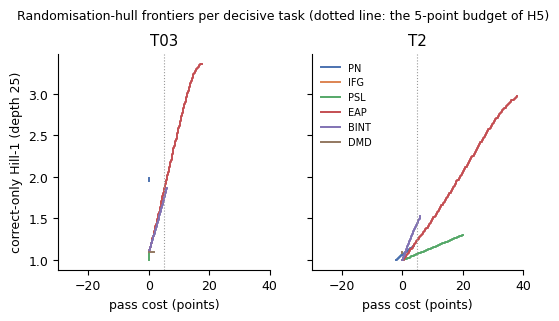

f2 ok


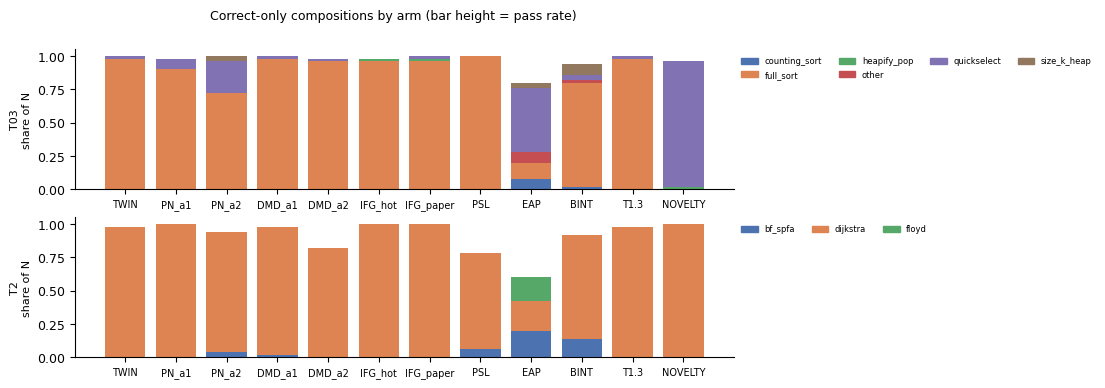

f3 ok


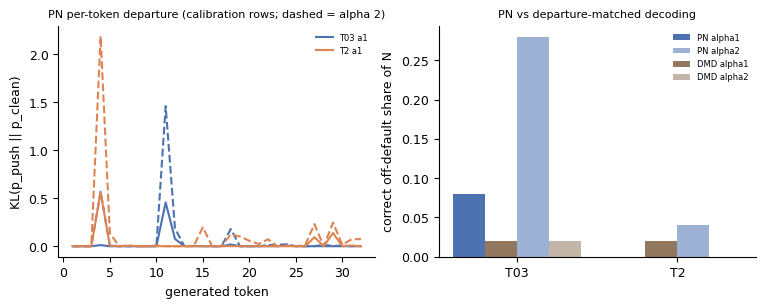

f4 ok


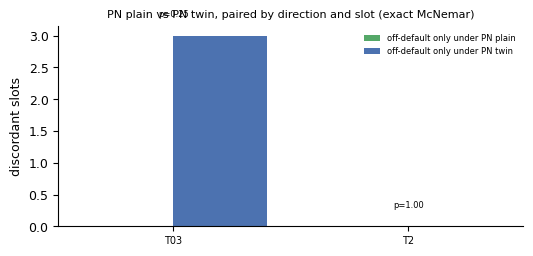

f5 ok


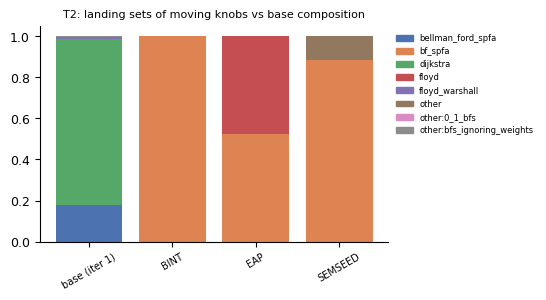

f6 ok


In [22]:
# ---- src/figures5.py (F2-F6), drawn from the results/*.json files written above (no recomputation).
# Notebook changes: figures are shown inline (no matplotlib.use("Agg"); save() shows the figure instead of closing
# it); the panels cover the decisive tasks of the subset (D5_FIG instead of D5); F4 reads the committed DMD
# calibration from data; F6 draws the path tasks present; F1 is skipped (it needs Claim F's literal-cell traces).
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False})
PAL = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974", "#64B5CD"]
CLS = ["PN", "IFG", "PSL", "EAP", "BINT", "DMD"]
D5_FIG = tuple(t for t in D5 if t in read_json(RESULTS_DIR / "prices.json"))  # notebook: the decisive tasks present


def save(fig, name: str) -> None:
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}", bbox_inches="tight", dpi=160)
    plt.show()  # notebook: was plt.close(fig)


def f2() -> None:
    pr = read_json(RESULTS_DIR / "prices.json")
    fig, axs = plt.subplots(1, len(D5_FIG), figsize=(3.0 * len(D5_FIG), 2.8), sharey=True)
    for ax, t in zip(axs, D5_FIG):
        for i, c in enumerate(CLS):
            p = pr.get(t, {}).get(c)
            if not p or not p.get("frontier"):
                continue
            fr = np.array(p["frontier"])
            ax.step(fr[:, 0] * 100, fr[:, 1], where="post", color=PAL[i], label=c, lw=1.4)
        ax.axvline(5, color="#999", ls=":", lw=0.8)
        ax.set_title(t)
        ax.set_xlabel("pass cost (points)")
        ax.set_xlim(-30, 40)
    axs[0].set_ylabel("correct-only Hill-1 (depth 25)")
    axs[-1].legend(fontsize=7, frameon=False)
    fig.suptitle("Randomisation-hull frontiers per decisive task (dotted line: the 5-point budget of H5)", fontsize=9,
                 y=1.04)
    save(fig, "F2_hull_frontiers")


def f3() -> None:
    cells = read_json(RESULTS_DIR / "cells.json")
    arms = ["TWIN", "PN_a1", "PN_a2", "DMD_a1", "DMD_a2", "IFG_hot", "IFG_paper", "PSL", "EAP", "BINT", "T1.3", "NOVELTY"]
    fig, axs = plt.subplots(len(D5_FIG), 1, figsize=(8.5, 2.0 * len(D5_FIG)))
    for ax, t in zip(axs, D5_FIG):
        present = [a for a in arms if f"{t}|{a}" in cells]
        labs = sorted({l for a in present for l in cells[f"{t}|{a}"]["correct_composition"]})
        col = {l: PAL[i % len(PAL)] for i, l in enumerate(labs)}
        for j, a in enumerate(present):
            c = cells[f"{t}|{a}"]
            bottom = 0.0
            for l in labs:
                v = c["correct_composition"].get(l, 0) / max(c["N"], 1)
                if v:
                    ax.bar(j, v, bottom=bottom, color=col[l], width=0.8)
                    bottom += v
        ax.set_xticks(range(len(present)), present, fontsize=7)
        ax.set_ylabel(f"{t}\nshare of N", fontsize=8)
        ax.legend([plt.Rectangle((0, 0), 1, 1, color=col[l]) for l in labs], labs, fontsize=6, ncol=4,
                  loc="upper left", bbox_to_anchor=(1.0, 1.0), frameon=False)
    fig.suptitle("Correct-only compositions by arm (bar height = pass rate)", fontsize=9)
    save(fig, "F3_compositions")


def f4() -> None:
    dmd = AUX["dmd_temperatures"]  # notebook: was read_json(PRED_DIR / "dmd_temperatures.json")
    pvd = read_json(RESULTS_DIR / "pn_vs_dmd.json")["per_task"]
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.0))
    for i, t in enumerate(D5_FIG):
        for a, ls in (("1.0", "-"), ("2.0", "--")):
            v = dmd.get(t, {}).get(a)
            if v:
                axs[0].plot(range(1, len(v["kl_curve_PN"]) + 1), v["kl_curve_PN"], ls=ls, color=PAL[i],
                            label=f"{t} a{a[0]}" if a == "1.0" else None)
    axs[0].set_xlabel("generated token")
    axs[0].set_ylabel("KL(p_push || p_clean)")
    axs[0].set_title("PN per-token departure (calibration rows; dashed = alpha 2)", fontsize=8)
    axs[0].legend(fontsize=6, frameon=False)
    x = np.arange(len(D5_FIG))
    wd = 0.2
    for k, (key, lab, c) in enumerate((("PN_off_default_share", "PN", PAL[0]), ("DMD_off_default_share", "DMD", PAL[5]))):
        for a, off in (("alpha1", -1.5), ("alpha2", 0.5)):
            vals = [pvd.get(t, {}).get(a, {}).get(key, np.nan) for t in D5_FIG]
            axs[1].bar(x + (off + k) * wd, vals, width=wd, color=c, alpha=1.0 if a == "alpha1" else 0.55,
                       label=f"{lab} {a}")
    axs[1].set_xticks(x, D5_FIG)
    axs[1].set_ylabel("correct off-default share of N")
    axs[1].set_title("PN vs departure-matched decoding", fontsize=8)
    axs[1].legend(fontsize=6, frameon=False)
    save(fig, "F4_pn_vs_dmd")


def f5() -> None:
    pvt = read_json(RESULTS_DIR / "plain_vs_twin.json")
    ts = [t for t in pvt if "PNPLAIN_a1_vs_PN_a1" in pvt[t]]
    fig, ax = plt.subplots(figsize=(6, 2.6))
    x = np.arange(len(ts))
    a = [pvt[t]["PNPLAIN_a1_vs_PN_a1"]["mcnemar"]["x_only"] for t in ts]
    b = [pvt[t]["PNPLAIN_a1_vs_PN_a1"]["mcnemar"]["y_only"] for t in ts]
    ax.bar(x - 0.2, a, 0.4, color=PAL[2], label="off-default only under PN plain")
    ax.bar(x + 0.2, b, 0.4, color=PAL[0], label="off-default only under PN twin")
    for i, t in enumerate(ts):
        p = pvt[t]["PNPLAIN_a1_vs_PN_a1"]["mcnemar"]["p_exact"]
        ax.text(i, max(a[i], b[i]) + 0.3, f"p={p:.2f}", ha="center", fontsize=6)
    ax.set_xticks(x, ts, fontsize=7)
    ax.set_ylabel("discordant slots")
    ax.set_title("PN plain vs PN twin, paired by direction and slot (exact McNemar)", fontsize=8)
    ax.legend(fontsize=6, frameon=False)
    save(fig, "F5_plain_vs_twin")


def f6() -> None:
    land = read_json(RESULTS_DIR / "landings.json")
    base = land["base_compositions_iter1"]
    path_tasks = tuple(t for t in ("T1", "T2") if t in D5_FIG)  # notebook: was ("T1", "T2")
    fig, axs = plt.subplots(1, len(path_tasks), figsize=(4.5 * len(path_tasks), 2.8), squeeze=False)  # was (1, 2)
    for ax, t in zip(axs[0], path_tasks):
        sets = {"base (iter 1)": Counter(base.get(t, {}))}
        for k, v in land["moves"].items():
            if k.startswith(t + "|") and v.get("moves"):
                sets[k.split("|")[1]] = Counter(v["landing_set"])
        labs = sorted({l for c in sets.values() for l in c})
        col = {l: PAL[i % len(PAL)] for i, l in enumerate(labs)}
        for j, (nm, c) in enumerate(sets.items()):
            tot = max(sum(c.values()), 1)
            bottom = 0.0
            for l in labs:
                v = c.get(l, 0) / tot
                if v:
                    ax.bar(j, v, bottom=bottom, color=col[l])
                    bottom += v
        ax.set_xticks(range(len(sets)), list(sets), rotation=30, fontsize=7)
        ax.set_title(f"{t}: landing sets of moving knobs vs base composition", fontsize=8)
        ax.legend([plt.Rectangle((0, 0), 1, 1, color=col[l]) for l in labs], labs, fontsize=6, frameon=False,
                  loc="upper left", bbox_to_anchor=(1.0, 1.0))
    save(fig, "F6_landings")


FIG_DIR.mkdir(exist_ok=True)
for f in (f2, f3, f4, f5, f6):
    try:
        f()
        print(f"{f.__name__} ok")
    except (FileNotFoundError, KeyError, ValueError, TypeError) as e:
        print(f"{f.__name__} skipped: {e}")

## 6. Results: the demo against the committed run

Each number recomputed here sits next to the committed value for the same task from the artifact's `results/`.

- **Exact matches expected.** The point prices and the McNemar counts are deterministic. They should match the committed run exactly, so the largest |ΔH5| below should be 0.0000.
- **Small differences expected.** The bootstrap CIs and P(PN ≥ best) come from the committed run's first `N_BOOT_D5` replicates, which are identical replicate by replicate. They differ from the committed values only because they use fewer replicates (500 instead of 2,000).
- **The verdict.** It is computed on 2 of the 5 decisive tasks with the code's own fallback threshold. It is not the committed 5-task verdict.

In [23]:
# ---- notebook: the numbers recomputed here next to the committed run's (artifact results/, same tasks)
ref = data["metadata"]["reference"]
CLASSES_SHOWN = ["PN", "IFG", "PSL", "EAP", "BINT", "DMD", "TEMP", "TOPK10", "NOVELTY", "SEMSEED"]


def fmt(x, nd=2):
    return "never" if x is None or (isinstance(x, float) and math.isinf(x)) else f"{x:.{nd}f}"


def fmt_ci(c):
    return "-" if not c or c[0] is None else f"[{c[0]:.2f}, {c[1]:.2f}]"


print(f"Knob prices on the demo subset ({len(boots[D5_DEMO[0]])} bootstrap replicates per task here, "
      f"{ref['claim_c']['n_replicates']} in the committed run)")
print("H5 = best correct-only Hill-1 at <= 5 pass points lost;  P15 = pass points needed to reach Hill 1.5\n")
print(f"{'task':4s} {'class':8s} | {'H5 here':>7s} {'committed':>9s} | {'95% CI here':>12s} {'committed CI':>12s} | "
      f"{'P15 here':>8s} {'committed':>9s}")
for t in D5_DEMO:
    for cls in CLASSES_SHOWN:
        if cls not in kt.get(t, {}):
            continue
        a, b = kt[t][cls], ref["knob_table"][t].get(cls, {})
        print(f"{t:4s} {cls:8s} | {fmt(a['H5']):>7s} {fmt(b.get('H5')):>9s} | {fmt_ci(a['H5_ci95']):>12s} "
              f"{fmt_ci(b.get('H5_ci95')):>12s} | {fmt(a['P15']):>8s} {fmt(b.get('P15')):>9s}")
    print()
dev = [abs(kt[t][c]["H5"] - ref["knob_table"][t][c]["H5"]) for t in D5_DEMO for c in kt[t] if c in ref["knob_table"][t]]
print(f"largest |H5 here - H5 committed| over {len(dev)} (task, class) point prices: {max(dev):.4f}\n")

print("Claim C per task: PN against the best text-level plan sampler")
for t in D5_DEMO:
    a, b = primary["per_task"][t], ref["claim_c"]["per_task"][t]
    print(f"  {t:4s} here:      PN {a['H5_PN']:.2f} vs {a['best_text_class']:4s} {a['best_text']:.2f} -> PN wins: "
          f"{a['PN_wins']!s:5s}  P(PN >= best) = {fmt(p_win.get(t), 3)}")
    print(f"  {'':4s} committed: PN {b['H5_PN']:.2f} vs {b['best_text_class']:4s} {b['best_text']:.2f} -> PN wins: "
          f"{b['PN_wins']!s:5s}  P(PN >= best) = {ref['claim_c']['p_PN_ge_best_text'][t]:.3f}")
print(f"  verdict on this {len(D5_DEMO)}-task subset: {primary['verdict']} (PN wins {primary['wins']}, threshold "
      f"{primary['threshold']});  committed verdict on all 5 decisive tasks: {ref['claim_c']['verdict_all_D5']} "
      f"(PN wins {ref['claim_c']['wins_all_D5']}, threshold {ref['claim_c']['threshold_all_D5']})\n")

print("PN vs departure-matched decoding: exact McNemar on 'correct and off-default' slots (PN-only / DMD-only)")
for t in D5_DEMO:
    for al in ("alpha1", "alpha2"):
        a, b = pvd["per_task"][t].get(al), ref["pn_vs_dmd"]["per_task"][t].get(al)
        if a and b:
            ma, mb = a["mcnemar_PN_vs_DMD"], b["mcnemar_PN_vs_DMD"]
            print(f"  {t:4s} {al}: here {ma['x_only']:2d}/{ma['y_only']:<2d} (p = {ma['p_exact']:.2g})   committed "
                  f"{mb['x_only']:2d}/{mb['y_only']:<2d} (p = {mb['p_exact']:.2g})")

Knob prices on the demo subset (500 bootstrap replicates per task here, 2000 in the committed run)
H5 = best correct-only Hill-1 at <= 5 pass points lost;  P15 = pass points needed to reach Hill 1.5

task class    | H5 here committed |  95% CI here committed CI | P15 here committed
T03  PN       |    1.98      1.98 | [1.63, 2.31] [1.64, 2.28] |     0.00      0.00
T03  IFG      |    1.19      1.19 | [1.00, 1.43] [1.00, 1.43] |    never     never
T03  PSL      |    1.09      1.09 | [1.00, 1.25] [1.00, 1.25] |    never     never
T03  EAP      |    1.83      1.83 | [1.43, 2.83] [1.43, 2.75] |     0.03      0.03
T03  BINT     |    1.73      1.73 | [1.27, 2.23] [1.25, 2.25] |     0.03      0.03
T03  DMD      |    1.10      1.10 | [1.00, 1.26] [1.00, 1.30] |    never     never
T03  TEMP     |    1.09      1.09 | [1.00, 1.26] [1.00, 1.30] |    never     never
T03  TOPK10   |    1.09      1.09 | [1.00, 1.26] [1.00, 1.26] |    never     never
T03  NOVELTY  |    2.03      2.03 | [1.96, 2.21] [1.9

### The knob map

**Top row.**
- **Points.** Every arm is a point at (pass-rate points lost against TWIN, correct-only Hill-1). TWIN is the star.
- **Lines.** The step lines are the **hull frontiers** of PN and of the best text sampler. They show what randomising between the settings of a class can buy.
- **Budget.** The dotted line is the 5-point budget that defines H5. A knob is valuable if its frontier rises steeply to the left of the line.

**Bottom row.** Each class's H5 recomputed here, as a dot with its bootstrap 95% CI. Next to it is the committed H5 (×) with its committed CI (grey).

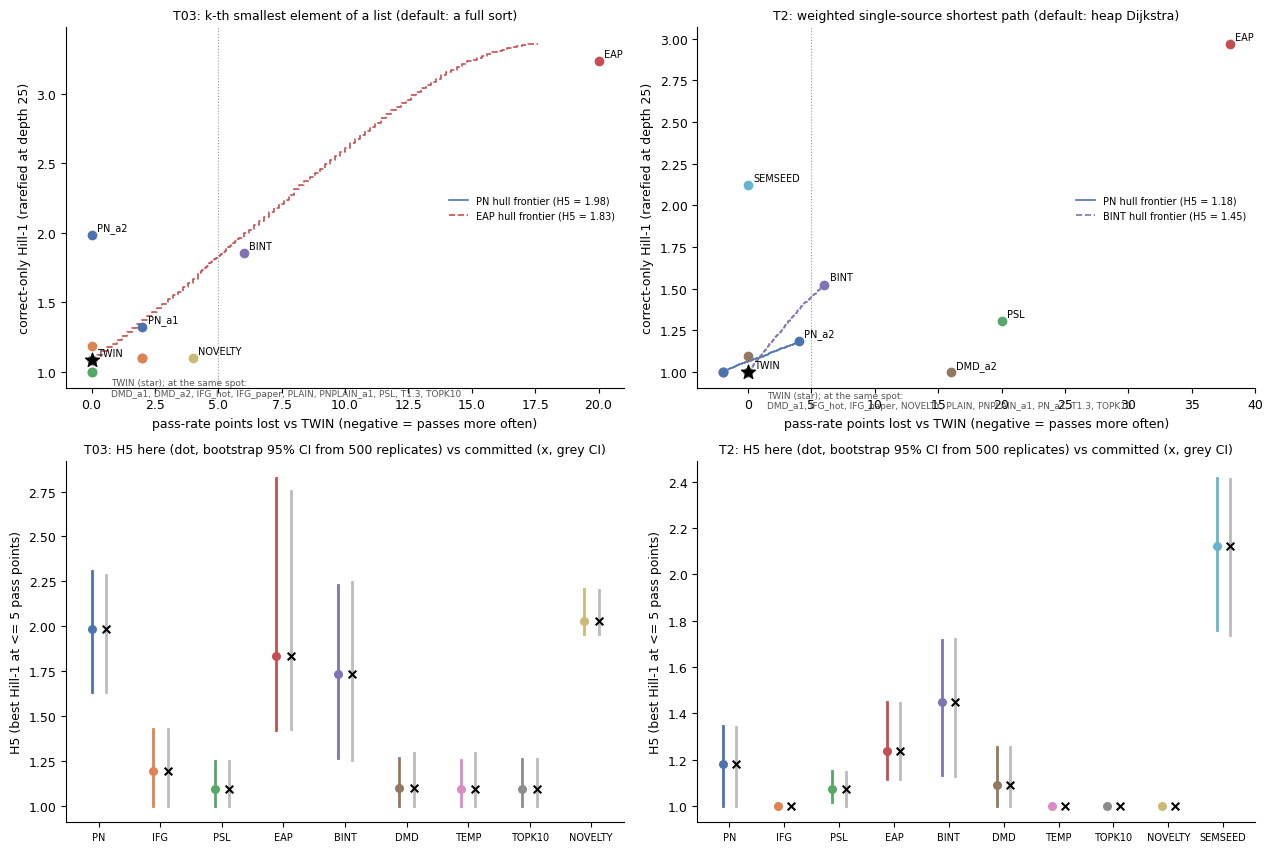

In [24]:
# ---- notebook: the knob map (top row) and the reproduction of the H5 prices (bottom row)
FAMILY_COL = {"REF": "#000000", "REF_PLAIN": "#8C8C8C", "PN": PAL[0], "PNPLAIN": "#9DB4E0", "IFG": PAL[1],
              "PSL": PAL[2], "EAP": PAL[3], "BINT": PAL[4], "DMD": PAL[5], "TEMP": PAL[6], "TOPK10": PAL[7],
              "NOVELTY": PAL[8], "SEMSEED": PAL[9]}
fig, axs = plt.subplots(2, len(D5_DEMO), figsize=(6.4 * len(D5_DEMO), 8.6), squeeze=False)
for col, t in enumerate(D5_DEMO):
    ax, axb = axs[0][col], axs[1][col]
    tw = cells[f"{t}|TWIN"]
    near_twin = []
    for (tt, a), cell in sorted(idx.items()):
        c = cells[f"{tt}|{a}"]
        if tt != t or c["hill_rarefied"] is None:
            continue
        x = (tw["pass"] - c["pass"]) * 100
        ax.scatter(x, c["hill_rarefied"], s=110 if a == "TWIN" else 36, marker="*" if a == "TWIN" else "o",
                   color=FAMILY_COL[ARMS5[a]["family"]], zorder=3)
        if a != "TWIN" and abs(x) <= 2.5 and abs(c["hill_rarefied"] - tw["hill_rarefied"]) <= 0.1:
            near_twin.append(a)  # arms that sit on TWIN: listed once instead of labelled one by one
        else:
            ax.annotate(a, (x, c["hill_rarefied"]), textcoords="offset points", xytext=(4, 3), fontsize=7)
    ax.annotate("TWIN (star); at the same spot:\n" + ", ".join(near_twin), (0, tw["hill_rarefied"]),
                textcoords="offset points", xytext=(14, -26), fontsize=6.5, color="#555555")
    for cls, ls in (("PN", "-"), (primary["per_task"][t]["best_text_class"], "--")):
        fr = np.array(prices[t][cls]["frontier"])
        ax.step(fr[:, 0] * 100, fr[:, 1], where="post", ls=ls, lw=1.2, color=FAMILY_COL[cls],
                label=f"{cls} hull frontier (H5 = {prices[t][cls]['H5']:.2f})")
    ax.axvline(5, color="#999", ls=":", lw=0.8)
    ax.set_xlabel("pass-rate points lost vs TWIN (negative = passes more often)")
    ax.set_ylabel("correct-only Hill-1 (rarefied at depth 25)")
    ax.set_title(f"{t}: {data['metadata']['task_descriptions'][t]}", fontsize=9)
    ax.legend(fontsize=7, frameon=False, loc="center right")
    cl = [c for c in CLASSES_SHOWN if c in kt[t] and c in ref["knob_table"][t]]
    for j, c in enumerate(cl):
        a, b = kt[t][c], ref["knob_table"][t][c]
        if a["H5_ci95"][0] is not None:
            axb.plot([j - 0.12] * 2, a["H5_ci95"], color=FAMILY_COL[c], lw=2)
        axb.scatter(j - 0.12, a["H5"], color=FAMILY_COL[c], s=30, zorder=3)
        if b["H5_ci95"][0] is not None:
            axb.plot([j + 0.12] * 2, b["H5_ci95"], color="#BBBBBB", lw=2)
        axb.scatter(j + 0.12, b["H5"], marker="x", color="k", s=30, zorder=3)
    axb.set_xticks(range(len(cl)), cl, fontsize=7)
    axb.set_ylabel("H5 (best Hill-1 at <= 5 pass points)")
    axb.set_title(f"{t}: H5 here (dot, bootstrap 95% CI from {len(boots[t])} replicates) vs committed (x, grey CI)",
                  fontsize=9)
plt.tight_layout()
plt.show()

### What a "creative" program looks like, and Claim F

The cell below prints two programs that are **correct but leave the task's default algorithm**:

- **T2, `BINT`.** The base model writes a one-sentence plan and the instruct model implements it. The plan is printed with the program.
- **T03, `PN_a2`.** Plan noise at α 2 alone moves the program away from a full sort.

The labels come from the artifact's frozen labellers (runtime trace + AST). On T03 their `quickselect` covers both pivot-partition selection (8 of PN_a2's 14 off-default programs) and a binary search over the value range (4 of 14, like the example printed below).

The cell then prints the committed **Claim F** result from the artifact's `results/literal_cell.json`. That is the temperature question on the shortest-path task with thinking on.

In [25]:
# ---- notebook: two correct programs that left the task's default, and the committed Claim-F result
def first_row(task, arm, pred):
    for ex in data["examples"]:
        if ex["task"] != task:
            continue
        for r in ex["rows"]:
            if r["arm"] == arm and pred(r):
                return ex, r
    return None, None


for task, arm in (("T2", "BINT"), ("T03", "PN_a2")):
    d = dfl[task]["default"]
    ex, r = first_row(task, arm, lambda r: r["passed"] and r["label"] != d and r.get("code"))
    if r is None:
        continue
    print(f"--- {task} / {arm} at slot {ex['input']}: TWIN wrote '{ex['output']}', this arm wrote '{r['label']}|pass'")
    if r.get("intent"):
        print("intent sentence (written by Qwen3-8B-Base):", r["intent"])
    print("\n".join(r["code"].splitlines()[:25]))
    print()

lc = ref["claim_f_literal_cell"]
print("Claim F, the literal cell (committed result; its 100 thinking traces are not part of this subset):")
print(f"  C_T = {lc['C_T']['n_change_final_label']} of {lc['C_T']['n_seeds_all4_completed']} seeds change the final-code "
      f"algorithm across T in {{0.3, 0.7, 1.0, 1.3}} (Clopper-Pearson one-sided 95% upper bound "
      f"{lc['C_T']['clopper_pearson']['upper95_one_sided']:.3f}); the first approach named changes on "
      f"{lc['C_T']['n_change_first_approach']}")
for arm, v in lc["per_T"].items():
    print(f"  {arm:13s} completed {v['completed']}/{v['n']}  final labels {v['final_label_composition']}  "
          f"first approach {v['first_approach_composition']}  median think tokens {v['think_tokens_median']:.0f}  "
          f"Dijkstra style {v['dijkstra_style']}")
nf, pe = lc["noise_floor"], lc["paired_exp21"]
print(f"  noise floor (T 0.7 vs its repeat, same seed): byte-identical thinking {nf['byte_identical_thinking']}/"
      f"{nf['n_pairs']}, label agreement {nf['label_agreement']:.2f}")
print(f"  vs exp21's same-seed top-p-1 run: label agreement {pe['label_agreement']:.2f} on {pe['n_pairs']} pairs, "
      f"median common token prefix {pe['common_prefix_tokens_quantiles']['0.5']:.0f} tokens")

--- T2 / BINT at slot T2|W1|k=0: TWIN wrote 'dijkstra|pass', this arm wrote 'bf_spfa|pass'
intent sentence (written by Qwen3-8B-Base): Calculate the shortest path weighted sum using Bellman-Ford algorithm
def solve(n, edges, s, t):
    if s == t:
        return 0
    dist = [float('inf')] * n
    dist[s] = 0
    for _ in range(n - 1):
        updated = False
        for u, v, w in edges:
            if dist[u] + w < dist[v]:
                dist[v] = dist[u] + w
                updated = True
        if not updated:
            break
    return dist[t] if dist[t] != float('inf') else -1

--- T03 / PN_a2 at slot T03|W2|k=7: TWIN wrote 'full_sort|pass', this arm wrote 'quickselect|pass'
def solve(nums, k):
    def count_less_equal(x):
        return sum(1 for num in nums if num <= x)
    
    left, right = min(nums), max(nums)
    while left < right:
        mid = (left + right) // 2
        if count_less_equal(mid) < k:
            left = mid + 1
        else:
            right = mid
  